# Használt autók eladási árának előrejelzése gépi tanulással

**Mini kutatás – Data Science kurzus, végső projekt** · Újvári Zoltán

## Absztrakt

A kutatás azt vizsgálja, mennyire pontosan becsülhető egy használt autó eladási ára öt alapadatból: a modellből (ami a gyártót is meghatározza), az üzemanyag-típusból, a motor méretéből, az autó korából és a futásteljesítményből. Az adathalmaz 50 000 eladást tartalmaz, 15 modellel. A 12 teljesen azonos sor eltávolítása után a rögzített 20%-os teszthalmazt az elején félretettük, és csak a végén, egyszer használtuk. A modelleket a fejlesztő halmazon, ugyanazon az 5 foldon hasonlítottuk össze. A fő mutatót előre választottuk: ez a **relatív hibát mérő RMSLE**, mert egy 500-as tévedés egy 2 000-es autónál súlyos, egy 60 000-esnél viszont elhanyagolható.

A modell-létra eredménye (RMSLE, 5 fold):
- átlag-modell: 1,363;
- naiv kereskedői szabály, azaz az azonos modell és évjárat mediánja: 0,364;
- tisztességes lineáris modell: 0,053;
- Random Forest: 0,044;
- gradient boosting log-céllal: 0,026.

Az out-of-fold diagnosztika szerint a hiba a nagyon régi, intenzíven használt autóknál koncentrálódik. Ebből következett a visszacsatolási kör hipotézise: az **évi futásteljesítmény** (futás ÷ kor), egy két oszlopból számolt jellemző, a fa-alapú modellnek is segít. A boosting hibája ettől mind az 5 foldon csökkent, 0,0259-ról 0,0204-re (páros javulás: 0,0055 ± 0,0016). A Random Forestnek viszont rontott.

A végleges modell a zárolt teszthalmazon **RMSLE = 0,0194** (95%-os bootstrap-intervallum: 0,0189–0,0201), RMSE = 310, WAPE = 1,17%. A teszt-autók 98%-ánál a becslés ±5%-on belül van. A modell a lineáris alapmodellnél és a naiv szabálynál is egyértelműen jobb: a páros bootstrap-intervallumok nem tartalmazzák a 0-t.

A legfontosabb korlát, hogy ez a pontosság valós piacon irreális. Az adatok 15,5%-ában a gyártási év korábbi, mint a modell piaci bevezetése (például 1984-es Prius vagy 718 Cayman). Ez megerősíti azt, amit a Kaggle-forrás neve (*Mock Dataset*) is jelez: az adat **szimulált**, és a modell egy kevés zajt tartalmazó árképző szabályt tanult meg, nem a valódi használtautó-piacot.

### A notebook felépítése

| Lépés | Fejezet |
|---|---|
| Kutatási kérdések, hipotézisek, célváltozó és mutatók | 1 |
| Adatgyűjtés, adatforrás | 2 |
| EDA és a változók magyarázata | 3–12 |
| Adattisztítás és a modellváltozók kiválasztása | 13 |
| A tanító és a teszt halmaz különválasztása | 14 |
| Mutatók | 15 |
| Baseline-ok és modellek tanítása, összehasonlítása | 16 |
| Out-of-fold diagnosztika | 17 |
| Visszacsatolási kör (új jellemző) | 18 |
| Záró teszt, bizonytalanság | 19 |
| Korlátok | 20 |
| Összegzés | 21 |

A teljes notebook egy átlagos laptopon kb. 1–2 perc alatt fut le. Minden véletlen lépés rögzített seeddel (`SEED = 42`) fut, ezért az eredmények újrafuttatva is megegyeznek.

## 1. Kutatási kérdések és hipotézisek

### Fő kutatási kérdés

**Mennyire pontosan becsülhető egy használt autó eladási ára a modell, az üzemanyag-típus, a motorméret, a kor és a futásteljesítmény alapján, és melyik modellcsalád adja a legkisebb relatív hibát?**

### Részletes kérdések

1. Milyen pontos egy egyszerű, kereskedői logikát követő szabály (azonos modell és évjárat mediánára), és mennyit javít rajta a gépi tanulás?
2. Jobb-e egy nemlineáris, fa-alapú modell, mint egy tisztességesen felépített lineáris modell?
3. Hol, mely autóknál téved a legjobb modell, és megmagyarázható-e ez a hiba egy új jellemzővel?

### Hipotézisek (az elemzés előtt rögzítve)

| # | Hipotézis | Miből gondoljuk? |
|---|---|---|
| **H1** | A log-transzformált célváltozóval tanított modell relatív hibája (RMSLE) kisebb, mint a nyers áron tanítotté. | Az ár erősen jobbra ferde (EDA, 7. fejezet), az értékvesztés pedig arányos jellegű. |
| **H2** | A fa-alapú ensemble (gradient boosting) jobb, mint a tisztességes lineáris modell. | Az ár–kor és ár–futás kapcsolat nemlineárisnak tűnik (9. fejezet), és modellenként eltérő lehet. |
| **H3** | Minden gépi tanulási modell jobb a naiv „modell × évjárat medián” szabálynál. | A szabály nem veszi figyelembe a futást és a motort. |
| **H4** | Az évi futásteljesítmény (futás ÷ kor) mint új jellemző a fa-alapú modell hibáját is csökkenti. | Egy két oszlopból képzett arányt a fa csak sok vágással tud közelíteni. A H4-et csak akkor teszteljük, ha a diagnosztika (17. fejezet) is erre mutat. |

### A célváltozó és a hibák ára

- **Mit jósolunk?** Egy autó eladási árát (`Price`, pénzegységben; a forrás nem jelöli a devizát).
- **Kinek?** Egy képzeletbeli használtautó-kereskedőnek, aki egy beérkező autó ajánlati árát akarja gyorsan, egységes módon kiszámolni.
- **Melyik hiba drágább?** A **túlbecslés** esetén az autó túl drágán kerül a kínálatba: tovább áll, raktározási költséget okoz, végül le kell árazni. Az **alulbecslés** esetén a kereskedő a valós értéknél olcsóbban veszi át vagy adja el, és ez közvetlen veszteség. Mindkettő nagyjából az autó értékével arányos kárt okoz. Ezért egyik irányt sem büntetjük erősebben, viszont a hibát **relatívan** mérjük.
- **Ebből következő fő mutató: RMSLE** (a logaritmikus hibák négyzetes átlagának gyöke). Kis értékeknél közelítőleg a tipikus százalékos hibát méri, szimmetrikus, és nem engedi, hogy a drága Porschék abszolút hibái elnyomják a sok olcsó autót. A mutatót **a modellezés előtt** rögzítjük, és a modellválasztás is ez alapján történik.
- **Kiegészítő mutatók:** RMSE és MAE pénzegységben (mekkora a tévedés „forintban”), WAPE (összesített százalékos hiba), R² (csak tájékoztató), valamint a **jósolt/tényleges összeg** aránya (rendszerszintű torzítás, ami a log-cél visszaalakításánál fontos).

## 2. Adatgyűjtés és adatforrás

- **Fájl:** `car_sales_data.csv`, pontosvesszővel tagolt CSV, 50 000 sor × 7 oszlop (gyártó, modell, motorméret, üzemanyag, gyártási év, futásteljesítmény, ár).
- **Forrás:** Kaggle, *Mock Dataset of Second-hand Car Sales* (feltöltő: msnbehdani): https://www.kaggle.com/datasets/msnbehdani/mock-dataset-of-second-hand-car-sales. Ahogy a neve is mondja, **mock, azaz kitalált (szimulált)** adathalmaz, amelyet gyakorlásra tettek közzé.
- **Miért ezt az adatot választottam?** Elég nagy (50 000 megfigyelés), nincsenek benne hiányzó értékek, és a célváltozó (ár) egyértelmű. A változók pedig a valós használtautó-árazás legfontosabb tényezői: a típus, a kor, a futás és a motor.
- **Mi nincs benne?** Az eladás dátuma, a sebességváltó, a felszereltség, az állapot, a sérülések és a földrajzi hely. Ezek a valóságban fontos ártényezők (lásd a korlátokat, 20. fejezet).
- **Fontos megfigyelés előre:** a szimulált jelleg az adatokból is kimutatható (13. fejezet). Ez meghatározza, hogy az eredményekből mire lehet következtetni.

A következő fejezetek (3–12) a korábban elkészített feltáró adatelemzést (EDA) tartalmazzák. Ezek változatlan kóddal futnak.

## 3. Könyvtárak és megjelenítési beállítások

A kód úgy készült, hogy a notebook és a `car_sales_data.csv` ugyanabban a mappában legyen. Ezért a fájl relatív útvonalról tölthető be, és a notebook könnyen újrafuttatható.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

def format_number(value):
    """Egész értékeknél elhagyja a .0-t, a törteket egy tizedesre formázza."""
    if pd.isna(value):
        return ""
    if isinstance(value, (int, np.integer)):
        return f"{value:d}"
    if isinstance(value, (float, np.floating)):
        rounded = round(float(value), 1)
        if rounded == 0:
            return "0"
        if rounded.is_integer():
            return f"{rounded:.0f}"
        return f"{rounded:.1f}"
    return value

def display_table(frame):
    display(frame.style.format(format_number, na_rep=""))

def heatmap_labels(frame):
    return frame.apply(lambda column: column.map(format_number))

DATA_PATH = Path("car_sales_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"A dataset nem található: {DATA_PATH.resolve()}")

## 4. Az adathalmaz betöltése és alapstruktúrája

A fájl pontosvesszővel tagolt CSV. A motor-méret tizedeselválasztója vessző, ezért a betöltéskor ezt ponttá alakítjuk a numerikus változó képzéséhez. Az eredeti szöveges oszlopot is megtartjuk, hogy az átalakítás ellenőrizhető legyen.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
required_columns = ["Manufacturer", "Model", "Engine size", "Fuel type", "Year of manufacture", "Mileage", "Price"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Hiányzó oszlop(ok): {missing_columns}")

df["Engine size (L)"] = pd.to_numeric(df["Engine size"].astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")
reference_year = int(df["Year of manufacture"].max()) + 1
df["Car age"] = reference_year - df["Year of manufacture"]
df["Log price"] = np.log1p(df["Price"])
df["Mileage per year"] = df["Mileage"] / df["Car age"].clip(lower=1)
display_table(df.head())
print(f"Megfigyelések száma: {len(df):,}".replace(",", " "))
print(f"Változók száma az új változókkal együtt: {df.shape[1]}")
print(f"Referenciaév a kor számításához: {reference_year}")

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price,Engine size (L),Car age,Log price,Mileage per year
0,Ford,Fiesta,"1,0",Petrol,2002,127300,3074,1,21,8,6061.9
1,Porsche,718 Cayman,"4,0",Petrol,2016,57850,49704,4,7,10.8,8264.3
2,Ford,Mondeo,"1,6",Diesel,2014,39190,24072,1.6,9,10.1,4354.4
3,Toyota,RAV4,"1,8",Hybrid,1988,210814,1705,1.8,35,7.4,6023.3
4,VW,Polo,"1,0",Petrol,2006,127869,4101,1,17,8.3,7521.7


Megfigyelések száma: 50 000
Változók száma az új változókkal együtt: 11
Referenciaév a kor számításához: 2023


## 5. Változók értelmezése

| Változó | Típus | Szerep / értelmezés |
|---|---|---|
| `Manufacturer` | kategorikus | A gyártó márkája; várhatóan erős csoportosító változó. |
| `Model` | kategorikus | A konkrét modell; magasabb részletességű, mint a márka. |
| `Engine size` | szöveges forrásmező | Tizedesvesszős literérték; a `Engine size (L)` numerikus változóban használjuk. |
| `Fuel type` | kategorikus | Benzin, dízel vagy hibrid; technológiai és piaci különbségeket jelezhet. |
| `Year of manufacture` | numerikus/diszkrét | A gyártási év; ebből képezzük az autó korát. |
| `Mileage` | numerikus | A futásteljesítmény; az ár várhatóan kapcsolatban áll vele. |
| `Price` | numerikus célváltozó | Az előrejelzendő eladási ár. |
| `Car age` | képzett numerikus | Az autó kora a referenciaévhez képest. |
| `Mileage per year` | képzett numerikus | A futásteljesítmény évesített közelítése. |
| `Log price` | képzett változó | Az ár ferdeségének csökkentésére használható. |

A képzett változók a meglévő mezők alternatív, elemzéshez hasznos reprezentációi.

## 6. Kezdeti adatminőségi audit

Az audit ellenőrzi a méretet, a hiányzó értékeket, a duplikációkat, az adattípusokat és a numerikus tartományokat. A szélsőértékek önmagukban nem feltétlenül hibák, ezért azokat külön vizualizációkkal is megvizsgáljuk.

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(dropna=False),
}).sort_values(["missing", "unique"], ascending=[False, True])
display_table(quality)
print(f"Teljesen duplikált sorok száma: {df.duplicated().sum():,}".replace(",", " "))
num_cols = ["Engine size (L)", "Year of manufacture", "Car age", "Mileage", "Mileage per year", "Price"]
numeric_summary = df[num_cols].describe().T
numeric_summary["skew"] = df[num_cols].skew()
display_table(numeric_summary)

,dtype,missing,missing_%,unique
Fuel type,str,0,0,3
Manufacturer,str,0,0,5
Engine size,str,0,0,14
Engine size (L),float64,0,0,14
Model,str,0,0,15
Year of manufacture,int64,0,0,39
Car age,int64,0,0,39
Price,int64,0,0,25045
Log price,float64,0,0,25045
Mileage,int64,0,0,44971


Teljesen duplikált sorok száma: 12


,count,mean,std,min,25%,50%,75%,max,skew
Engine size (L),50000,1.8,0.7,1,1.4,1.6,2,5,2.1
Year of manufacture,50000,2004.2,9.6,1984,1996,2004,2012,2022,-0.1
Car age,50000,18.8,9.6,1,11,19,27,39,0.1
Mileage,50000,112497.3,71632.5,630,54352.2,100987.5,158601,453537,0.7
Mileage per year,50000,5986.2,2002.9,500,4635,5995.9,7338,13865.6,0
Price,50000,13828.9,16416.7,76,3060.8,7971.5,19026.5,168081,2.9


### Adatminőségi értelmezés

- A szükséges mezők kitöltöttek, és a CSV minden sora azonos szerkezetű.
- A `Engine size` átalakítása után minden motor-méret numerikusan értelmezhető.
- Az ár és a futásteljesítmény ferdeségét érdemes figyelembe venni: a szélsőértékek a későbbi modell hibamértékeit befolyásolhatják.
- 12 teljesen azonos sor van. Mivel a folytonos futás és ár is egyezik, valószínűleg duplán rögzített eladásokról van szó; a kezelésüket a 13. fejezet indokolja.

## 7. A célváltozó: az eladási ár eloszlása

Az ábra a célváltozó szintjét és log-transzformált változatát mutatja. A logaritmikus változat segíthet a ferde eloszlás és a magas árú megfigyelések hatásának értelmezésében.

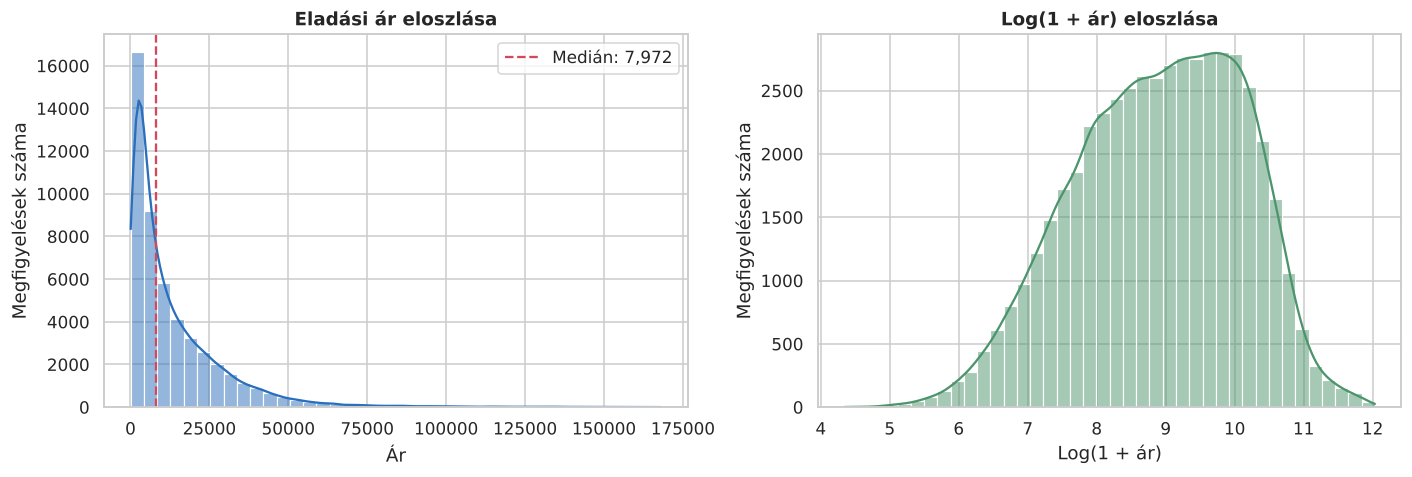

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["Price"], bins=40, kde=True, color="#2a6fbb", ax=axes[0])
axes[0].axvline(df["Price"].median(), color="#d1495b", linestyle="--", label=f"Medián: {df['Price'].median():,.0f}")
axes[0].set_title("Eladási ár eloszlása"); axes[0].set_xlabel("Ár"); axes[0].set_ylabel("Megfigyelések száma"); axes[0].legend()
sns.histplot(df["Log price"], bins=40, kde=True, color="#4c956c", ax=axes[1])
axes[1].set_title("Log(1 + ár) eloszlása"); axes[1].set_xlabel("Log(1 + ár)"); axes[1].set_ylabel("Megfigyelések száma")
plt.tight_layout(); plt.show()

## 8. Kategorikus változók és csoportkülönbségek

A darabszámok megmutatják, hogy mennyire kiegyensúlyozottak a kategóriák. A boxplotok a csoportok ár-eloszlásait hasonlítják össze; a kiugró pontokat elrejtjük, hogy 50 000 rekord mellett is olvasható maradjon az ábra.

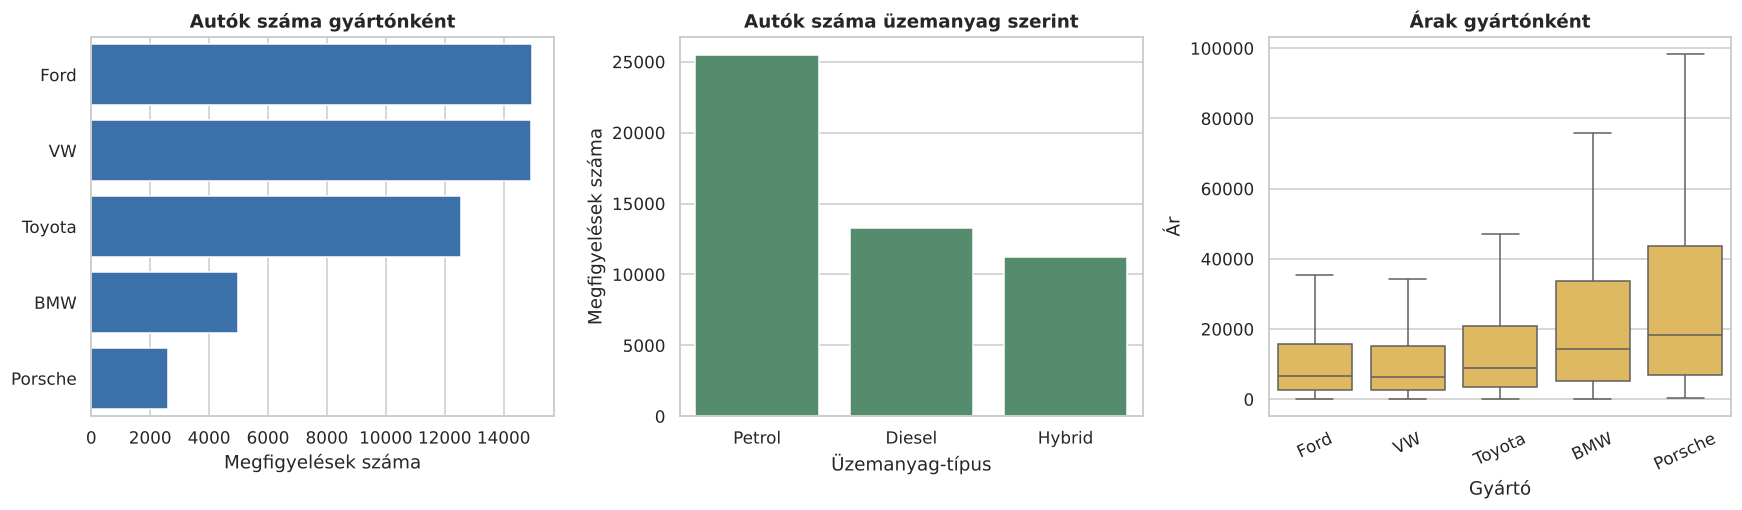

,count,median_price,mean_price
Manufacturer,,,
Porsche,2609,18441,29103.8
BMW,4965,14384,24429.5
Toyota,12554,8802,14340.4
Ford,14959,6646,10672.3
VW,14913,6428,10363.1


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
manufacturer_order = df["Manufacturer"].value_counts().index
sns.countplot(data=df, y="Manufacturer", order=manufacturer_order, color="#2a6fbb", ax=axes[0])
axes[0].set_title("Autók száma gyártónként"); axes[0].set_xlabel("Megfigyelések száma"); axes[0].set_ylabel("")
fuel_order = df["Fuel type"].value_counts().index
sns.countplot(data=df, x="Fuel type", order=fuel_order, color="#4c956c", ax=axes[1])
axes[1].set_title("Autók száma üzemanyag szerint"); axes[1].set_xlabel("Üzemanyag-típus"); axes[1].set_ylabel("Megfigyelések száma")
sns.boxplot(data=df, x="Manufacturer", y="Price", order=manufacturer_order, color="#f2c14e", showfliers=False, ax=axes[2])
axes[2].set_title("Árak gyártónként"); axes[2].set_xlabel("Gyártó"); axes[2].set_ylabel("Ár"); axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
manufacturer_summary = df.groupby("Manufacturer")["Price"].agg(count="size", median_price="median", mean_price="mean").sort_values("median_price", ascending=False)
display_table(manufacturer_summary)

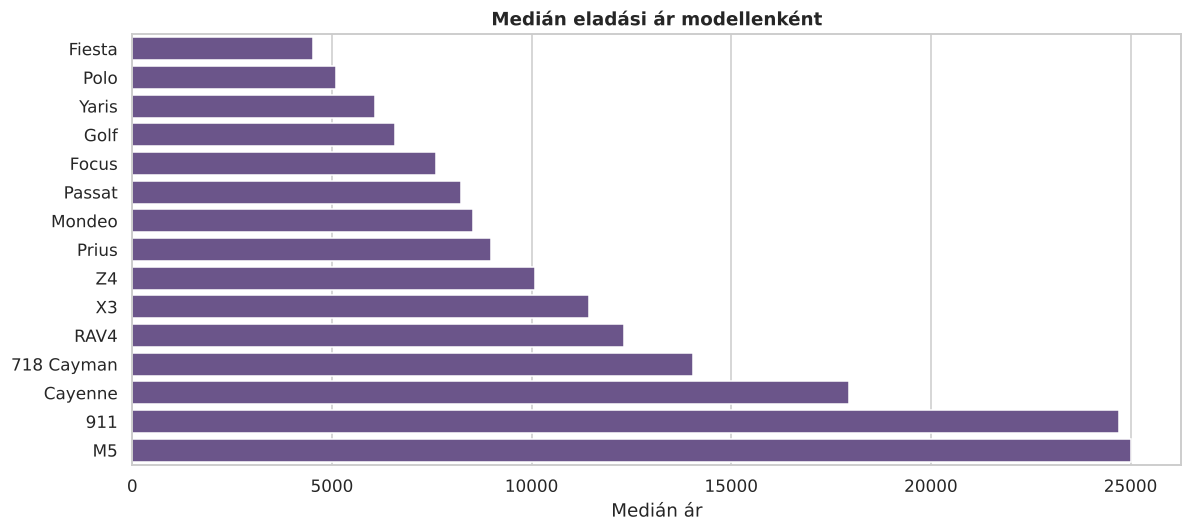

,count,median_price
Model,,
M5,1645,25022
911,872,24706.5
Cayenne,870,17936.5
718 Cayman,867,14031
RAV4,4292,12305
X3,1632,11448.5
Z4,1688,10082.5
Prius,4171,8989
Mondeo,5058,8543.5


In [6]:
model_summary = df.groupby("Model")["Price"].agg(count="size", median_price="median").sort_values("median_price", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=model_summary.sort_values("median_price").reset_index(), y="Model", x="median_price", color="#6a4c93", ax=ax)
ax.set_title("Medián eladási ár modellenként"); ax.set_xlabel("Medián ár"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
display_table(model_summary)

## 9. Numerikus változók és az ár kapcsolata

A pontdiagramok a legfontosabb numerikus magyarázó változók és az ár kapcsolatát mutatják. A színezés az üzemanyag-típust jelöli, így csoportonként eltérő mintázatok is láthatóvá válhatnak. Ezek leíró ábrák, nem végleges regressziós eredmények.

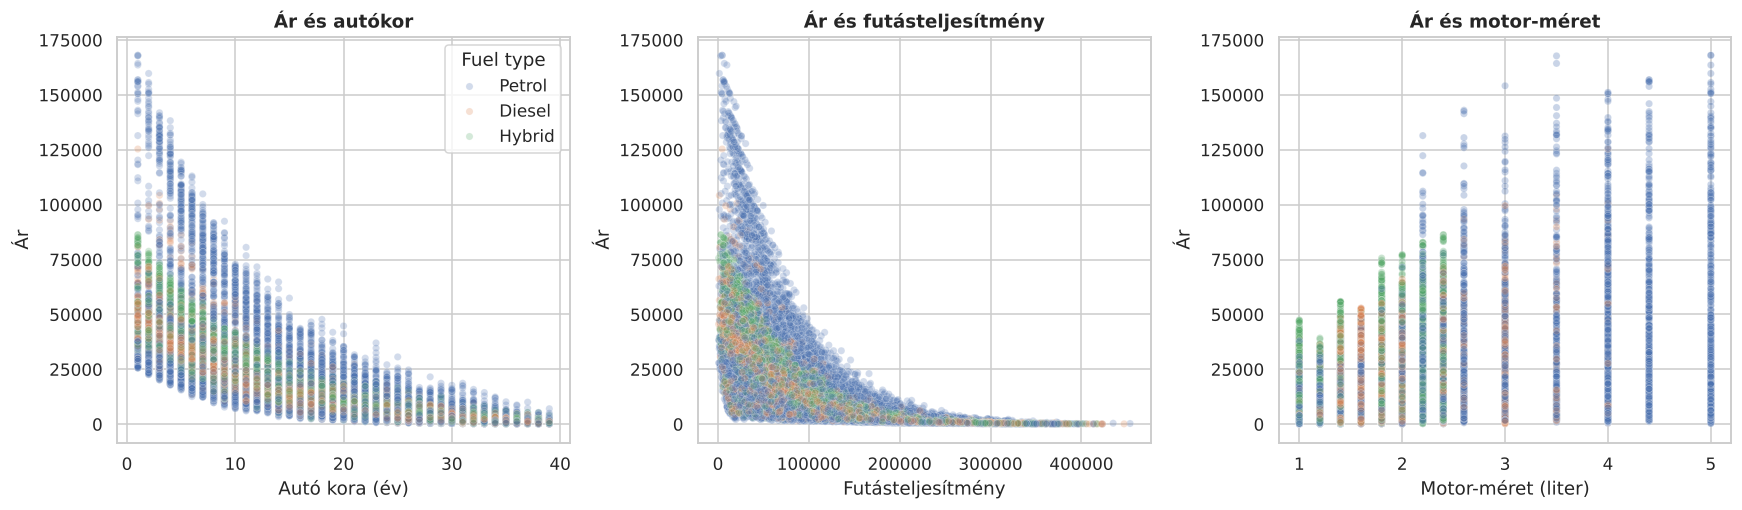

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.scatterplot(data=df, x="Car age", y="Price", hue="Fuel type", alpha=0.25, s=22, ax=axes[0])
axes[0].set_title("Ár és autókor"); axes[0].set_xlabel("Autó kora (év)"); axes[0].set_ylabel("Ár")
sns.scatterplot(data=df, x="Mileage", y="Price", hue="Fuel type", alpha=0.25, s=22, legend=False, ax=axes[1])
axes[1].set_title("Ár és futásteljesítmény"); axes[1].set_xlabel("Futásteljesítmény"); axes[1].set_ylabel("Ár")
sns.scatterplot(data=df, x="Engine size (L)", y="Price", hue="Fuel type", alpha=0.3, s=22, legend=False, ax=axes[2])
axes[2].set_title("Ár és motor-méret"); axes[2].set_xlabel("Motor-méret (liter)"); axes[2].set_ylabel("Ár")
plt.tight_layout(); plt.show()

## 10. Korrelációs áttekintés

A Pearson-korreláció numerikus változók lineáris együttmozgását méri. Kategorikus változókat nem tartalmaz, és nem bizonyít oksági kapcsolatot. Emiatt ezt az ábrát csak iránytűként használjuk; a kategorikus változók hatását a csoportos ábrák egészítik ki.

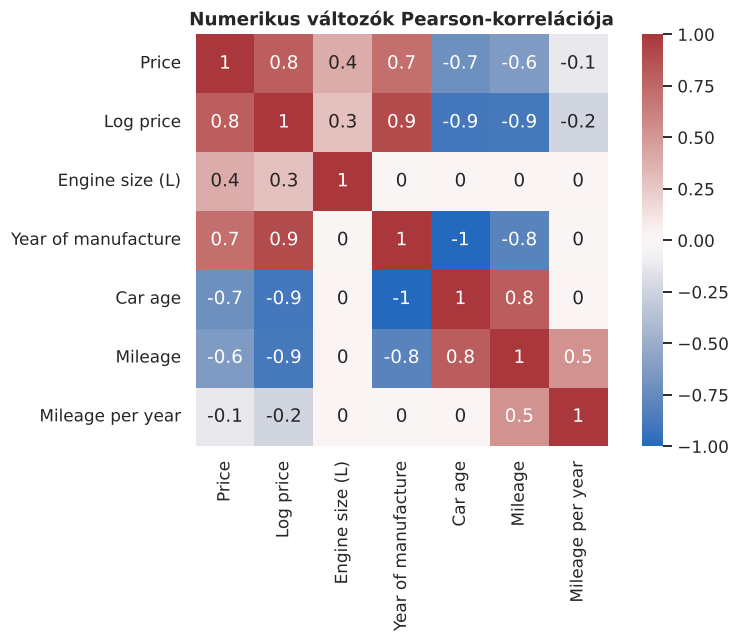

,korreláció az árral
Log price,0.8
Year of manufacture,0.7
Car age,-0.7
Mileage,-0.6
Engine size (L),0.4
Mileage per year,-0.1


In [8]:
correlation_columns = ["Price", "Log price", "Engine size (L)", "Year of manufacture", "Car age", "Mileage", "Mileage per year"]
corr = df[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=heatmap_labels(corr), fmt="", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Numerikus változók Pearson-korrelációja")
plt.tight_layout(); plt.show()
display_table(corr["Price"].drop("Price").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("korreláció az árral"))

## 11. Többváltozós nézet: gyártó és üzemanyag-típus

Az egyetlen csoportosítás könnyen elrejthet összetett mintázatokat. Ezért a következő ábra a gyártó és az üzemanyag-típus együttes csoportjait mutatja mediánárral. A medián kevésbé érzékeny a szélsőséges árakra, mint az átlag.

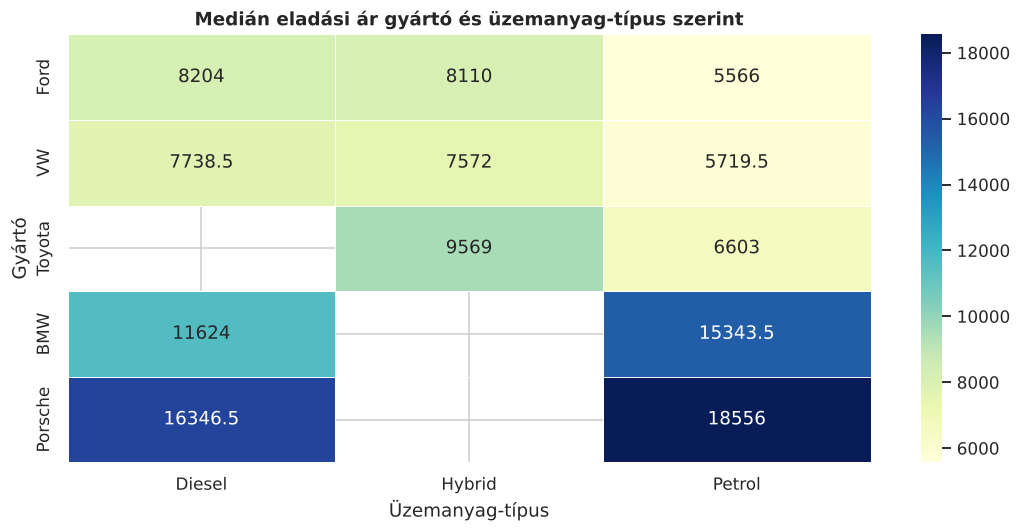

Fuel type,Diesel,Hybrid,Petrol
Manufacturer,,,
Ford,8204,8110,5566
VW,7738.5,7572,5719.5
Toyota,,9569,6603
BMW,11624,,15343.5
Porsche,16346.5,,18556


In [9]:
median_table = df.pivot_table(index="Manufacturer", columns="Fuel type", values="Price", aggfunc="median").reindex(index=manufacturer_order)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(median_table, annot=heatmap_labels(median_table), fmt="", cmap="YlGnBu", linewidths=0.5, ax=ax)
ax.set_title("Medián eladási ár gyártó és üzemanyag-típus szerint"); ax.set_xlabel("Üzemanyag-típus"); ax.set_ylabel("Gyártó")
plt.tight_layout(); plt.show(); display_table(median_table)

## 12. Az EDA tanulságai a modellezéshez

- Az adathalmaz jól strukturált, nincs hiányzó érték, és a motorméret számmá alakítható. **12 teljesen azonos sor** van, ezeket a 13. fejezetben kezeljük.
- Az ár **erősen jobbra ferde**, a log-transzformált ár viszont közel szimmetrikus. Ezért a modelleket log-célon tanítjuk, és ezt a H1-ben ellenőrizzük is.
- A **kor** és a **futásteljesítmény** a legerősebb numerikus magyarázó változók, és egymással is erősen korrelálnak. Ezért érdekes lehet a kettő aránya, az évi futás.
- A **modell** szerinti árkülönbségek nagyok, egy Porsche 911 és egy Ford Fiesta mediánja nagyságrendileg eltér. A modellt ezért kategóriaként kell kezelni (dummy-változókkal), nem számként.
- Az ár–kor kapcsolat nem egyenes, ami a nemlineáris modelleknek kedvez (H2).
- Az EDA-ábrák leíró jellegűek: együttmozgást mutatnak, nem oksági hatást.

## 13. Adattisztítás és a modellváltozók kiválasztása

Ebben a fejezetben minden adattisztítási döntés mellé indoklás tartozik. A tisztítás **nem tanul a célváltozóból** (nem számol átlagárat, nem imputál, nem skáláz). Ezért a split előtt is elvégezhető, szivárgás nélkül.

In [10]:
import time
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

SEED = 42                      # minden véletlen lépés (split, foldok, modellek) ugyanezzel a seeddel fut
rng = np.random.default_rng(SEED)

In [11]:
original_columns = ["Manufacturer", "Model", "Engine size", "Fuel type", "Year of manufacture", "Mileage", "Price"]
data = df.copy()
n_before = len(data)
data = data.drop_duplicates(subset=original_columns).reset_index(drop=True)
print(f"Teljesen azonos sorok eltávolítva: {n_before - len(data)} db  ->  {len(data):,} megfigyelés marad".replace(",", " "))

# Egy modell pontosan egy gyártóhoz tartozik-e? (Ha igen, a gyártó a modellből levezethető.)
models_per_manufacturer = data.groupby("Model")["Manufacturer"].nunique()
print("Minden modell pontosan egy gyártóhoz tartozik:", bool((models_per_manufacturer == 1).all()))

# Engine size: tizedesvessző -> szám; az átalakítás után nem maradhat hiányzó érték
print("Hiányzó motor-méret az átalakítás után:", int(data["Engine size (L)"].isna().sum()))
print("Legkisebb autókor (év):", int(data["Car age"].min()), "| legnagyobb:", int(data["Car age"].max()))

Teljesen azonos sorok eltávolítva: 12 db  ->  49 988 megfigyelés marad
Minden modell pontosan egy gyártóhoz tartozik: True
Hiányzó motor-méret az átalakítás után: 0
Legkisebb autókor (év): 1 | legnagyobb: 39


**Döntések és indokok:**

- **A 12 teljesen azonos sort eltávolítjuk.** Mind a hét mező egyezik, a folytonos futásteljesítmény és ár is. Ennek véletlen egybeesésként nagyon kicsi az esélye, ezért valószínűleg duplán rögzített eladásokról van szó. Ha bent maradnának, ugyanaz az autó kerülhetne a tanító és a teszt halmazba is, ami optimistán torzítaná a teszteredményt.
- **A gyártó (`Manufacturer`) nem kerül a modellbe.** Minden modell pontosan egy gyártóhoz tartozik, így a gyártó a modellből levezethető, új információt nem hordoz. Lineáris modellben ráadásul tökéletes multikollinearitást okozna a modell-dummykkal.
- **A kor referenciaéve 2023** (a legkésőbbi gyártási év + 1). Mivel az eladás dátuma nem ismert, ez közelítés, de a gyártási évvel egyenértékű információ. Így minden autó kora legalább 1 év, tehát az évi futás számításánál nincs 0-val osztás.
- **A szélsőséges értékeket nem töröljük.** A legolcsóbb autók (76–500 egység) mind nagyon régiek és sokat futottak. Ez belsőleg konzisztens, és pont az ilyen autók becslése a nehéz, ezért kidobásuk szépítené az eredményt.

In [12]:
# A modellek valós piaci bevezetésének éve (közismert gyártói adatok, kerekítve).
# Ezt csak plauzibilitás-ellenőrzésre használjuk, a modellbe NEM kerül be.
launch_year = {
    "Fiesta": 1976, "Focus": 1998, "Mondeo": 1993, "Polo": 1975, "Golf": 1974, "Passat": 1973,
    "Yaris": 1999, "Prius": 1997, "RAV4": 1994, "Z4": 2002, "X3": 2003, "M5": 1985,
    "911": 1964, "Cayenne": 2002, "718 Cayman": 2016,
}
plaus = (data.assign(launch=data["Model"].map(launch_year))
             .assign(before_launch=lambda d: d["Year of manufacture"] < d["launch"])
             .groupby("Model")
             .agg(legkorabbi_ev=("Year of manufacture", "min"), piaci_bevezetes=("launch", "first"),
                  bevezetes_elotti_sorok_pct=("before_launch", "mean")))
plaus["bevezetes_elotti_sorok_pct"] *= 100
display_table(plaus.sort_values("bevezetes_elotti_sorok_pct", ascending=False))
share_impossible = (data["Year of manufacture"] < data["Model"].map(launch_year)).mean() * 100
print(f"A sorok {share_impossible:.1f}%-ában a gyártási év korábbi, mint a modell piaci bevezetése.")

,legkorabbi_ev,piaci_bevezetes,bevezetes_elotti_sorok_pct
Model,,,
718 Cayman,1984,2016,83.3
X3,1984,2003,44.6
Z4,1984,2002,42.9
Cayenne,1984,2002,39.4
Yaris,1984,1999,31.6
Focus,1984,1998,29.2
Prius,1984,1997,26.2
RAV4,1984,1994,16.8
Mondeo,1984,1993,13.4


A sorok 15.5%-ában a gyártási év korábbi, mint a modell piaci bevezetése.


**Plauzibilitás-ellenőrzés: ez a kutatás egyik legfontosabb megállapítása.**

A modellek valós piaci bevezetésének éve közismert (például a Toyota Prius 1997-ben jelent meg, a Porsche 718 Cayman 2016-ban). Az adatban viszont **minden** modellnek van 1984-es példánya, és a sorok **15,5%-ában** a gyártási év korábbi, mint a modell létezése. A 718 Cayman-sorok 83%-a „lehetetlen”.

Mit kezdünk ezzel?

- **A sorokat nem töröljük.** Ha törölnénk őket, a modell a megmaradó adaton ugyanazt a mintázatot tanulná meg, csak kevesebb adatból. A teszthalmaz ugyanabból a forrásból származik, így a belső összehasonlítás (melyik modell jobb) érvényes marad.
- **Az értelmezést viszont korlátozzuk.** Az adat **szimulált**: a forrás neve (*Mock Dataset*) is ezt jelzi, és ez az ellenőrzés az adatokból is igazolja. Egy árképző képlet és véletlen zaj állította elő, nem valódi eladások. Ezért ha később „túl jó” pontosságot kapunk, az nem a modell zsenialitását mutatja, hanem azt, hogy a generátor kevés zajt tett az árakba. Valós piacra az eredmény nem vihető át közvetlenül (lásd a 20. fejezetet).

In [13]:
TARGET = "Price"
CAT = ["Model", "Fuel type"]                                  # kategorikus: one-hot (lineáris, fa, RF) / natív kategória (boosting)
NUM_BASE = ["Engine size (L)", "Car age", "Mileage"]          # numerikus alapjellemzők
NUM_FE = NUM_BASE + ["Mileage per year"]                      # a visszacsatolási körben kipróbált bővítés

feature_table = pd.DataFrame([
    ("Model", "bemegy (one-hot / kategória)", "15 modell; a gyártót teljesen tartalmazza"),
    ("Fuel type", "bemegy (one-hot / kategória)", "3 kategória, a modellen belül is változik"),
    ("Engine size (L)", "bemegy", "a szöveges mező számmá alakítva"),
    ("Car age", "bemegy", "2023 − gyártási év; a gyártási évvel egyenértékű"),
    ("Mileage", "bemegy", "futásteljesítmény"),
    ("Manufacturer", "kimarad", "a Model-ből levezethető (beágyazott), új információt nem hoz"),
    ("Year of manufacture", "kimarad", "a Car age lineáris átírása; kettő együtt redundáns"),
    ("Log price", "kimarad", "a célváltozó transzformációja: bemenetként szivárgás lenne"),
    ("Mileage per year", "csak a 18. fejezetben", "hipotézisként teszteljük, nem eleve adjuk a modellnek"),
], columns=["változó", "döntés", "indok"])
display(feature_table)

,változó,döntés,indok
0,Model,bemegy (one-hot / kategória),15 modell; a gyártót teljesen tartalmazza
1,Fuel type,bemegy (one-hot / kategória),"3 kategória, a modellen belül is változik"
2,Engine size (L),bemegy,a szöveges mező számmá alakítva
3,Car age,bemegy,2023 − gyártási év; a gyártási évvel egyenértékű
4,Mileage,bemegy,futásteljesítmény
5,Manufacturer,kimarad,"a Model-ből levezethető (beágyazott), új információt nem hoz"
6,Year of manufacture,kimarad,a Car age lineáris átírása; kettő együtt redundáns
7,Log price,kimarad,a célváltozó transzformációja: bemenetként szivárgás lenne
8,Mileage per year,csak a 18. fejezetben,"hipotézisként teszteljük, nem eleve adjuk a modellnek"


**A modellekbe kerülő változók:** 2 kategorikus (`Model`, `Fuel type`) és 3 numerikus (`Engine size (L)`, `Car age`, `Mileage`).

Az **évi futásteljesítményt** az EDA-ban már kiszámoltuk, de szándékosan **nem** adjuk eleve a modellnek. Csak akkor tesztelünk új jellemzőt, ha a diagnosztika (17. fejezet) hipotézist ad rá. Így a visszacsatolási kör őszinte kísérlet marad, nem utólagos magyarázat.

## 14. A tanító és a teszt halmaz különválasztása

**A split minden modellezési döntés előtt történik.** A teszthalmazt ettől a ponttól a 19. fejezetig nem nézzük meg: rajta nem választunk modellt, jellemzőt vagy mutatót.

- **Arány: 80/20.** 50 000 sor mellett 10 000 teszt-autó elég ahhoz, hogy a teszt-hiba szűk bizonytalansági intervallummal becsülhető legyen, és a tanításra is bőven marad adat.
- **Véletlenszerű, modell szerint rétegzett vágás.** Az adatban nincs eladási dátum, ezért időrendi vágást nem lehet alkalmazni, és nincs is jövőből tanulás veszélye. A rétegzés miatt mind a 15 modell ugyanakkora arányban kerül a tanító és a teszt halmazba. A ritkább Porschék így nem maradhatnak ki véletlenül a tesztből.
- **Ugyanaz az autó nem kerülhet mindkét oldalra:** a duplikátumokat a 13. fejezetben eltávolítottuk. Más azonosító (pl. alvázszám) nincs, ezért a többször eladott autókat nem tudjuk felismerni; ez korlát.
- **Keresztvalidáció:** a fejlesztő (tanító) halmazon 5 rétegzett fold, **ugyanazok a foldok minden modellnek**. Így a modellek foldonként párban összehasonlíthatók.

In [14]:
dev, test = train_test_split(data, test_size=0.20, stratify=data["Model"], random_state=SEED)
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)

# Ugyanaz az 5 fold minden modellnek (a modellenkénti összehasonlítás így páros)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(dev, dev["Model"]))

print(f"Fejlesztő (tanító) halmaz: {len(dev):,} sor | zárolt teszthalmaz: {len(test):,} sor".replace(",", " "))
print("Foldméretek (validációs rész):", [len(va) for _, va in folds])
split_check = pd.DataFrame({
    "fejlesztő": dev[TARGET].describe()[["mean", "50%", "min", "max"]],
    "teszt": test[TARGET].describe()[["mean", "50%", "min", "max"]],
}).T
display_table(split_check)

Fejlesztő (tanító) halmaz: 39 990 sor | zárolt teszthalmaz: 9 998 sor
Foldméretek (validációs rész): [7998, 7998, 7998, 7998, 7998]


,mean,50%,min,max
fejlesztő,13837.2,7979.5,76,168081
teszt,13796.9,7930,135,159778


A fejlesztő és a teszt halmaz árainak átlaga és mediánja szinte azonos (13 837 vs 13 797; 7 980 vs 7 930), vagyis a vágás nem torzít.

## 15. Mutatók: mit mérünk és miért

| Mutató | Mit mér? | Miért nézzük? |
|---|---|---|
| **RMSLE** (fő) | a log-hibák négyzetes átlagának gyöke ≈ tipikus relatív hiba | Az árazási hiba költsége az autó értékével arányos (1. fejezet). Az olcsó és a drága autók hibája így azonos súlyú. |
| RMSE | a hibák négyzetes átlagának gyöke, pénzegységben | A nagy abszolút tévedéseket bünteti; a drága autók dominálják. |
| MAE | átlagos abszolút hiba, pénzegységben | Könnyen kommunikálható: „átlagosan ennyit tévedünk”. |
| WAPE | összes abszolút hiba ÷ összes tényleges ár | Portfólió-szintű százalékos hiba; nem robban fel a nagyon olcsó autóknál, ellentétben a MAPE-vel. |
| R² | a megmagyarázott variancia aránya | Csak tájékoztató: nagy szórású célnál könnyen „szép”, de keveset mond a hibáról. |
| jósolt/tényleges összeg | rendszerszintű torzítás | A log-célú modellek visszaalakításkor alulbecsülhetnek; ez kimutatja. |

In [15]:
def regression_metrics(y_true, y_pred):
    """A projekt összes mutatója egy helyen. A jóslatot 0-nál alulról vágjuk (ár nem lehet negatív)."""
    y = np.asarray(y_true, dtype=float)
    p = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    err = y - p
    return {
        "RMSLE": float(np.sqrt(np.mean((np.log1p(y) - np.log1p(p)) ** 2))),   # FŐ MUTATÓ (relatív hiba)
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "MAE": float(np.mean(np.abs(err))),
        "WAPE_%": float(np.abs(err).sum() / y.sum() * 100),
        "R2": float(1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum()),
        "jósolt/tényleges összeg": float(p.sum() / y.sum()),
    }

def fold_scores(y_true, y_pred, metric="RMSLE"):
    """A fő mutató foldonként (a fejlesztő halmaz out-of-fold jóslatain)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.array([regression_metrics(y_true[va], y_pred[va])[metric] for _, va in folds])

print("Példa: tökéletes jóslat ->", {k: round(v, 3) for k, v in regression_metrics([1000, 2000], [1000, 2000]).items()})

Példa: tökéletes jóslat -> {'RMSLE': 0.0, 'RMSE': 0.0, 'MAE': 0.0, 'WAPE_%': 0.0, 'R2': 1.0, 'jósolt/tényleges összeg': 1.0}


## 16. Modellek tanítása: baseline-ok és modell-létra

A modelleket „létraként” állítjuk sorba, a legegyszerűbbtől a legösszetettebbig. Egy modell csak akkor ér valamit, ha megveri az alatta lévő fokokat.

| Modell | Szerep | Beállítás és indok |
|---|---|---|
| **Átlag** | legalsó viszonyítási pont | A tanító fold átlagárát jósolja mindenkinek. |
| **Naiv szabály** | kereskedői hüvelykujjszabály | Az azonos modell és gyártási év mediánára a tanító foldból; ha ilyen nincs, a modell mediánja. |
| **Lineáris (Ridge)** | tisztességes lineáris alapmodell | Log-cél, modell- és üzemanyag-dummyk, standardizált numerikus változók, enyhe L2-regularizáció (α = 1). Nem „gyenge szalmabáb”, amit könnyű megverni. |
| **Döntési fa** | egyetlen fa | max. mélység 12, min. 5 megfigyelés levelenként (a túltanulás korlátozására). |
| **Random Forest** | fák átlaga (bagging) | 200 fa, min. 2 megfigyelés levelenként, vágásonként a változók 50%-a. |
| **Gradient boosting** | fák egymás hibáit javítják | Az sklearn `HistGradientBoostingRegressor` (az XGBoost/LightGBM sklearn-es megfelelője), natív kategóriakezeléssel. Legfeljebb 500 fa, tanulási ráta 0,05, belső korai leállítással; ez utóbbi csak a tanító fold egy részét használja, ezért nincs szivárgás. Nyers és log-célon is tanítjuk (H1). |

A hiperparamétereket **előre, ésszerű kiinduló értékekre** rögzítettük, és nem hangoltuk őket. Így a modellek összehasonlítása nem azon múlik, melyiket hangoltuk tovább. Minden modell ugyanazon az 5 foldon, **out-of-fold** jóslatokkal kerül értékelésre: minden fejlesztő-sort olyan modell jósol meg, amelyik nem látta tanítás közben.

In [16]:
def onehot_preprocessor(num_cols, scale):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])

def make_linear(num_cols):          # "tisztességes" lineáris: log-cél, modell- és üzemanyag-dummyk, skálázott számok
    return make_pipeline(onehot_preprocessor(num_cols, scale=True), Ridge(alpha=1.0))

def make_tree(num_cols):
    return make_pipeline(onehot_preprocessor(num_cols, scale=False),
                         DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=SEED))

def make_forest(num_cols):
    return make_pipeline(onehot_preprocessor(num_cols, scale=False),
                         RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5,
                                               n_jobs=-1, random_state=SEED))

def make_boosting(num_cols):        # hisztogram-alapú gradient boosting (az XGBoost/LightGBM sklearn-es megfelelője)
    pre = ColumnTransformer([("cat", OrdinalEncoder(), CAT), ("num", "passthrough", num_cols)])
    return make_pipeline(pre, HistGradientBoostingRegressor(categorical_features=[0, 1], max_iter=500,
                                                            learning_rate=0.05, random_state=SEED))

def oof_predict(make_model, num_cols, log_target=True, frame=None):
    """Out-of-fold jóslat a fejlesztő halmazra: minden sort olyan modell jósol, amelyik nem látta."""
    frame = dev if frame is None else frame
    X, y = frame[CAT + num_cols], frame[TARGET]
    pred = np.zeros(len(frame))
    for tr, va in folds:
        model = make_model(num_cols)
        model.fit(X.iloc[tr], np.log1p(y.iloc[tr]) if log_target else y.iloc[tr])
        p = model.predict(X.iloc[va])
        pred[va] = np.expm1(p) if log_target else p
    return pred

def oof_mean():
    pred = np.zeros(len(dev))
    for tr, va in folds:
        pred[va] = dev[TARGET].iloc[tr].mean()
    return pred

def naive_rule(train, target_rows):
    """Naiv kereskedői szabály: azonos modell + azonos gyártási év mediánára a tanítóból; ha nincs ilyen, a modell mediánja."""
    by_model_year = train.groupby(["Model", "Year of manufacture"])[TARGET].median()
    by_model = train.groupby("Model")[TARGET].median()
    keys = pd.MultiIndex.from_frame(target_rows[["Model", "Year of manufacture"]])
    pred = pd.Series(by_model_year.reindex(keys).to_numpy(), index=target_rows.index)
    return pred.fillna(target_rows["Model"].map(by_model)).to_numpy()

def oof_naive():
    pred = np.zeros(len(dev))
    for tr, va in folds:
        pred[va] = naive_rule(dev.iloc[tr], dev.iloc[va])
    return pred

### 16.1 Eredmények a fejlesztő halmazon (5 fold, out-of-fold)

In [17]:
oof = {}
timings = {}
ladder_spec = [
    ("Átlag (tanító)",              lambda: oof_mean()),
    ("Naiv szabály (modell × év medián)", lambda: oof_naive()),
    ("Lineáris (Ridge, log-cél)",   lambda: oof_predict(make_linear, NUM_BASE)),
    ("Döntési fa (log-cél)",        lambda: oof_predict(make_tree, NUM_BASE)),
    ("Random Forest (log-cél)",     lambda: oof_predict(make_forest, NUM_BASE)),
    ("Gradient boosting (nyers cél)", lambda: oof_predict(make_boosting, NUM_BASE, log_target=False)),
    ("Gradient boosting (log-cél)", lambda: oof_predict(make_boosting, NUM_BASE)),
]
for name, fn in ladder_spec:
    t0 = time.time()
    oof[name] = fn()
    timings[name] = time.time() - t0

y_dev = dev[TARGET].to_numpy()
rows = []
for name, pred in oof.items():
    m = regression_metrics(y_dev, pred)
    fs = fold_scores(y_dev, pred)
    rows.append({"modell": name, **m, "RMSLE foldonként (átlag ± szórás)": f"{fs.mean():.4f} ± {fs.std():.4f}",
                 "futásidő (s)": timings[name]})
ladder = pd.DataFrame(rows).set_index("modell").sort_values("RMSLE")
display(ladder.style.format({"RMSLE": "{:.4f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "WAPE_%": "{:.2f}",
                             "R2": "{:.4f}", "jósolt/tényleges összeg": "{:.4f}", "futásidő (s)": "{:.1f}"}))

,RMSLE,RMSE,MAE,WAPE_%,R2,jósolt/tényleges összeg,RMSLE foldonként (átlag ± szórás),futásidő (s)
modell,,,,,,,,
Gradient boosting (log-cél),0.0259,342,168,1.22,0.9996,0.9996,0.0259 ± 0.0021,6.8
Gradient boosting (nyers cél),0.0428,351,187,1.35,0.9995,1.0002,0.0428 ± 0.0022,7.0
Random Forest (log-cél),0.0437,690,301,2.18,0.9982,0.9942,0.0437 ± 0.0016,16.7
"Lineáris (Ridge, log-cél)",0.0527,"1,552",642,4.64,0.9911,1.0152,0.0527 ± 0.0005,0.1
Döntési fa (log-cél),0.1244,"1,805","1,025",7.41,0.9879,0.9958,0.1244 ± 0.0015,0.4
Naiv szabály (modell × év medián),0.3643,"3,149","2,084",15.06,0.9633,0.9830,0.3643 ± 0.0040,0.0
Átlag (tanító),1.3626,"16,427","11,387",82.29,-0.0000,1.0000,1.3626 ± 0.0065,0.0


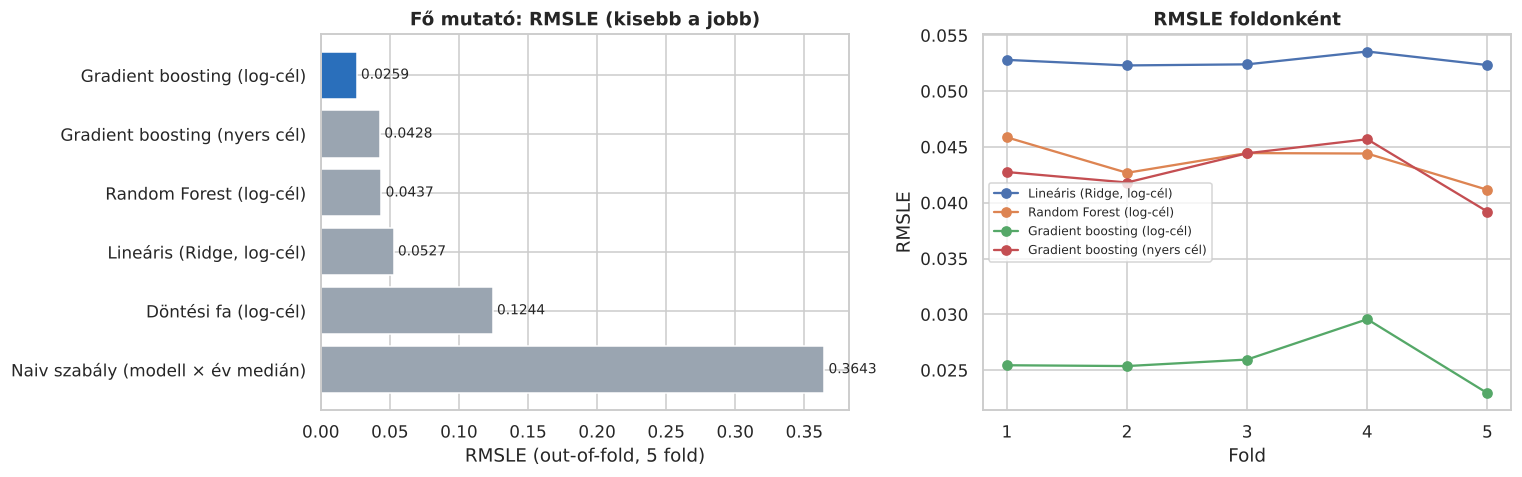

In [18]:
plot_df = ladder.drop(index="Átlag (tanító)")["RMSLE"].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ["#2a6fbb" if "boosting (log" in n else "#9aa5b1" for n in plot_df.index]
axes[0].barh(plot_df.index[::-1], plot_df.values[::-1], color=colors[::-1])
axes[0].set_title("Fő mutató: RMSLE (kisebb a jobb)"); axes[0].set_xlabel("RMSLE (out-of-fold, 5 fold)")
for i, v in enumerate(plot_df.values[::-1]):
    axes[0].text(v, i, f" {v:.4f}", va="center", fontsize=9)
# foldonkénti RMSLE: a különbségek nagyobbak-e a foldok közti ingadozásnál?
for name in ["Lineáris (Ridge, log-cél)", "Random Forest (log-cél)", "Gradient boosting (log-cél)", "Gradient boosting (nyers cél)"]:
    axes[1].plot(range(1, 6), fold_scores(y_dev, oof[name]), marker="o", label=name)
axes[1].set_title("RMSLE foldonként"); axes[1].set_xlabel("Fold"); axes[1].set_ylabel("RMSLE"); axes[1].set_xticks(range(1, 6))
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Értelmezés:**

- **Baseline-ok:** az átlag-modell RMSLE-je 1,363, ami gyakorlatilag használhatatlan. A naiv szabály (0,364; WAPE 15,1%) már sokat tud, mert a modell és az évjárat az ár nagy részét meghatározza. Minden gépi tanulási modell nagyságrenddel jobb ennél, így a **H3 teljesül**.
- **H2 – teljesül:** a log-célú gradient boosting RMSLE-je 0,0259, a tisztességes lineárisé 0,0527, vagyis a hiba kb. a felére csökken. A különbség mind az 5 foldon fennáll, és sokszorosa a foldok közti szórásnak (±0,002). Az egyetlen döntési fa (0,124) a lineárisnál is rosszabb: egyetlen fa lépcsős függvénnyel közelít, és ez a folytonos értékvesztést rosszul követi. A Random Forest (0,044) a lineárisnál jobb, a boostingnál gyengébb.
- **H1 – teljesül:** ugyanaz a boosting log-célon RMSLE 0,0259, nyers célon 0,0428. Az RMSE-ben a kettő közel azonos (342 vs 351), mert a nyers célú modell a drága autókra optimalizál, az olcsókat viszont relatívan rosszabbul becsüli.
- **A log-visszaalakítás torzítása elhanyagolható:** a boosting jósolt/tényleges összege 0,9996, vagyis 0,04%-kal becsüli alá az összértéket. A lineáris modell viszont 1,5%-kal felülbecsül. Ez nem a log-transzformáció hibája (az alulbecslést okozna), hanem a rossz funkcionális formáé, amit a 17.5 fejezet mutat meg.
- **Gyanús-e a „túl jó” szám?** Az R² 0,9996, a tipikus relatív hiba ~2,6%. Valós használtautó-piacon ez irreális, de összhangban van a 13. fejezet megállapításával, hogy az adat szimulált és kevés zajt tartalmaz. Szivárgásra nincs jel: a célváltozóból számolt jellemző nincs a modellben, a duplikátumokat eltávolítottuk, és a foldok közti szórás kicsi és egyenletes.

**A további diagnosztikát a legjobb modellen, a log-célú gradient boostingon végezzük.**

## 17. Out-of-fold diagnosztika a legjobb modellen

Egyetlen szám (RMSLE) nem mondja meg, **hol** és **hogyan** téved a modell. A diagnosztikát a fejlesztő halmaz out-of-fold jóslatain végezzük, nem a teszten. Így a belőle levont következtetéseket (például egy új jellemzőt) utána tisztán, a teszt érintése nélkül lehet ellenőrizni.

A **log-reziduum** = log(1 + tényleges) − log(1 + jósolt): ha pozitív, a modell alulbecsült, ha negatív, túlbecsült, és nagysága kb. a relatív hiba.

In [19]:
BEST = "Gradient boosting (log-cél)"
diag = dev.copy()
diag["pred"] = oof[BEST]
diag["log_resid"] = np.log1p(diag[TARGET]) - np.log1p(diag["pred"])   # > 0: alulbecslés, < 0: túlbecslés
diag["resid"] = diag[TARGET] - diag["pred"]
print(f"Diagnosztizált modell: {BEST}; out-of-fold jóslatok száma: {len(diag):,}".replace(",", " "))

Diagnosztizált modell: Gradient boosting (log-cél); out-of-fold jóslatok száma: 39 990


### 17.1 Kalibráció (decilisek)

,jósolt_átlag,tényleges_átlag,log_reziduum_átlag,log_reziduum_szórás,tényleges/jósolt
pred_decile,,,,,
D1,897,898,+0.0004,0.0595,1.0016
D2,"1,936","1,936",-0.0005,0.0232,0.9996
D3,"3,105","3,103",-0.0009,0.0209,0.9994
D4,"4,625","4,629",+0.0006,0.0211,1.0009
D5,"6,688","6,694",+0.0008,0.0210,1.0009
D6,"9,572","9,577",+0.0002,0.0195,1.0005
D7,"13,537","13,548",+0.0007,0.0172,1.0008
D8,"19,106","19,101",-0.0003,0.0154,0.9998
D9,"27,356","27,364",+0.0001,0.0137,1.0003


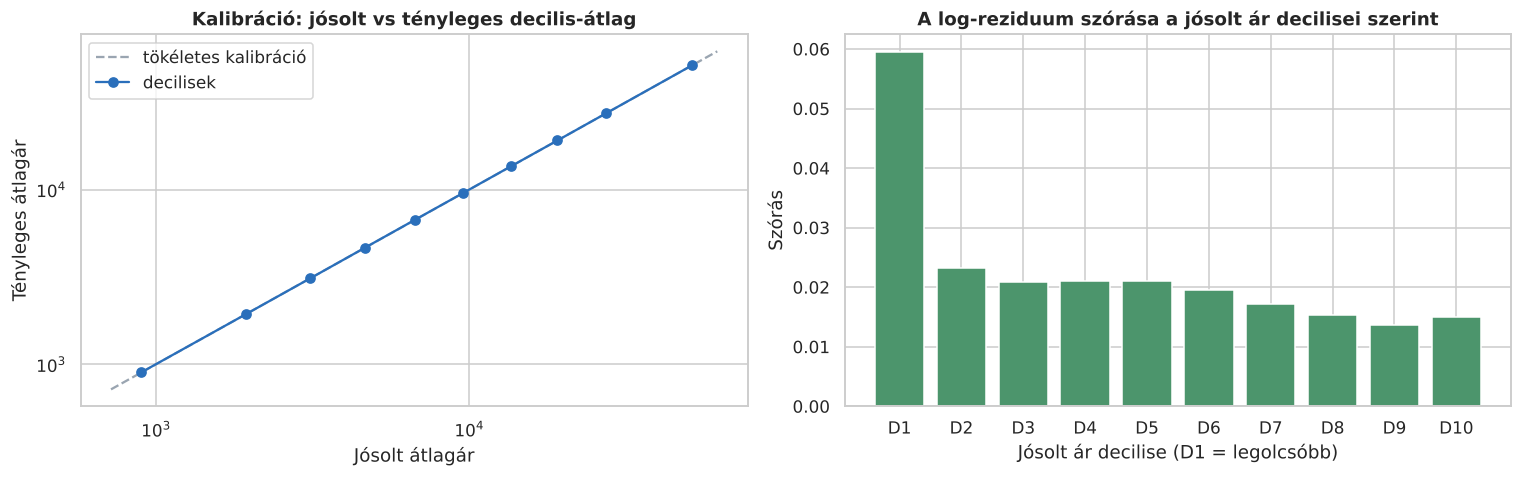

In [20]:
diag["pred_decile"] = pd.qcut(diag["pred"], 10, labels=[f"D{i}" for i in range(1, 11)])
calib = diag.groupby("pred_decile", observed=True).agg(
    jósolt_átlag=("pred", "mean"), tényleges_átlag=(TARGET, "mean"),
    log_reziduum_átlag=("log_resid", "mean"), log_reziduum_szórás=("log_resid", "std"))
calib["tényleges/jósolt"] = calib["tényleges_átlag"] / calib["jósolt_átlag"]
display(calib.style.format({"jósolt_átlag": "{:,.0f}", "tényleges_átlag": "{:,.0f}", "log_reziduum_átlag": "{:+.4f}",
                            "log_reziduum_szórás": "{:.4f}", "tényleges/jósolt": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lim = [calib[["jósolt_átlag", "tényleges_átlag"]].min().min() * 0.8, calib[["jósolt_átlag", "tényleges_átlag"]].max().max() * 1.2]
axes[0].plot(lim, lim, color="#9aa5b1", linestyle="--", label="tökéletes kalibráció")
axes[0].plot(calib["jósolt_átlag"], calib["tényleges_átlag"], marker="o", color="#2a6fbb", label="decilisek")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Kalibráció: jósolt vs tényleges decilis-átlag"); axes[0].set_xlabel("Jósolt átlagár"); axes[0].set_ylabel("Tényleges átlagár"); axes[0].legend()
axes[1].bar(calib.index.astype(str), calib["log_reziduum_szórás"], color="#4c956c")
axes[1].set_title("A log-reziduum szórása a jósolt ár decilisei szerint"); axes[1].set_xlabel("Jósolt ár decilise (D1 = legolcsóbb)"); axes[1].set_ylabel("Szórás")
plt.tight_layout(); plt.show()

**Mit látunk?** A jósolt ár mind a 10 decilisében a tényleges és a jósolt átlag aránya 0,999 és 1,002 közé esik. A modell tehát sem az olcsó, sem a drága autókat nem becsüli szisztematikusan alá vagy fölé, a kalibráció kiváló. A log-reziduum **szórása** viszont a legolcsóbb decilisben (D1) 0,059, a többiben csak 0,014–0,023.

**Mit tennék?** A kalibráción nincs mit javítani. A legolcsóbb autók 2–4-szer nagyobb relatív szórásának viszont utána kell járni, mert itt a hiba nem torzítás, hanem bizonytalanság.

### 17.2 Reziduum a becsült érték függvényében (tölcsér?)

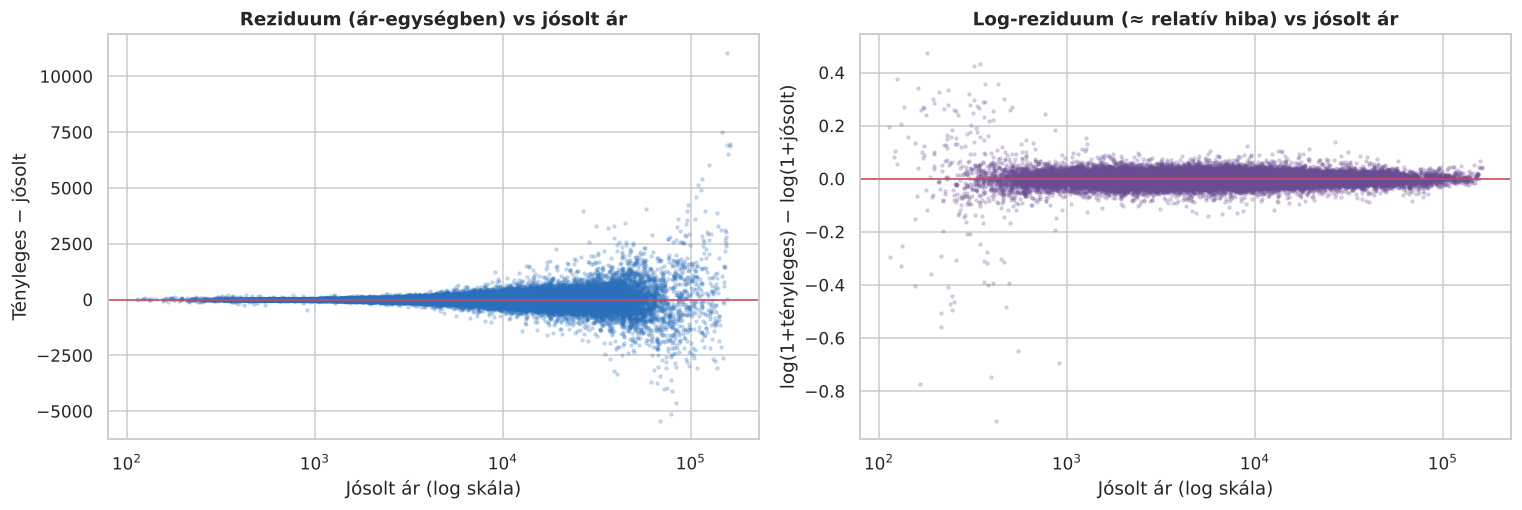

RMSE ár-egységben a legolcsóbb (D1) és a legdrágább (D10) decilisben: 29 vs 901


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(diag["pred"], diag["resid"], s=4, alpha=0.2, color="#2a6fbb")
axes[0].axhline(0, color="#d1495b", linewidth=1)
axes[0].set_xscale("log"); axes[0].set_title("Reziduum (ár-egységben) vs jósolt ár")
axes[0].set_xlabel("Jósolt ár (log skála)"); axes[0].set_ylabel("Tényleges − jósolt")
axes[1].scatter(diag["pred"], diag["log_resid"], s=4, alpha=0.2, color="#6a4c93")
axes[1].axhline(0, color="#d1495b", linewidth=1)
axes[1].set_xscale("log"); axes[1].set_title("Log-reziduum (≈ relatív hiba) vs jósolt ár")
axes[1].set_xlabel("Jósolt ár (log skála)"); axes[1].set_ylabel("log(1+tényleges) − log(1+jósolt)")
plt.tight_layout(); plt.show()
abs_by_dec = diag.groupby("pred_decile", observed=True)["resid"].agg(lambda r: np.sqrt(np.mean(r ** 2)))
print("RMSE ár-egységben a legolcsóbb (D1) és a legdrágább (D10) decilisben:",
      f"{abs_by_dec.iloc[0]:,.0f} vs {abs_by_dec.iloc[-1]:,.0f}".replace(",", " "))

**Mit látunk?** Pénzegységben klasszikus **tölcsér** rajzolódik ki: a hiba abszolút nagysága az árral együtt nő, a legolcsóbb decilisben az RMSE 29, a legdrágábban 901. Relatív (log) skálán a tölcsér megfordul: a legolcsóbb autóknál a legnagyobb a szóródás.

**Mit tennék?** Az abszolút tölcsér várható és rendben van, ezért választottunk relatív fő mutatót és log-célt. A bal szélen (olcsó autók) kiszóródó pontokat szegmensenként kell megvizsgálni.

### 17.3 Reziduum szegmensenként: kor, évi futás, modell

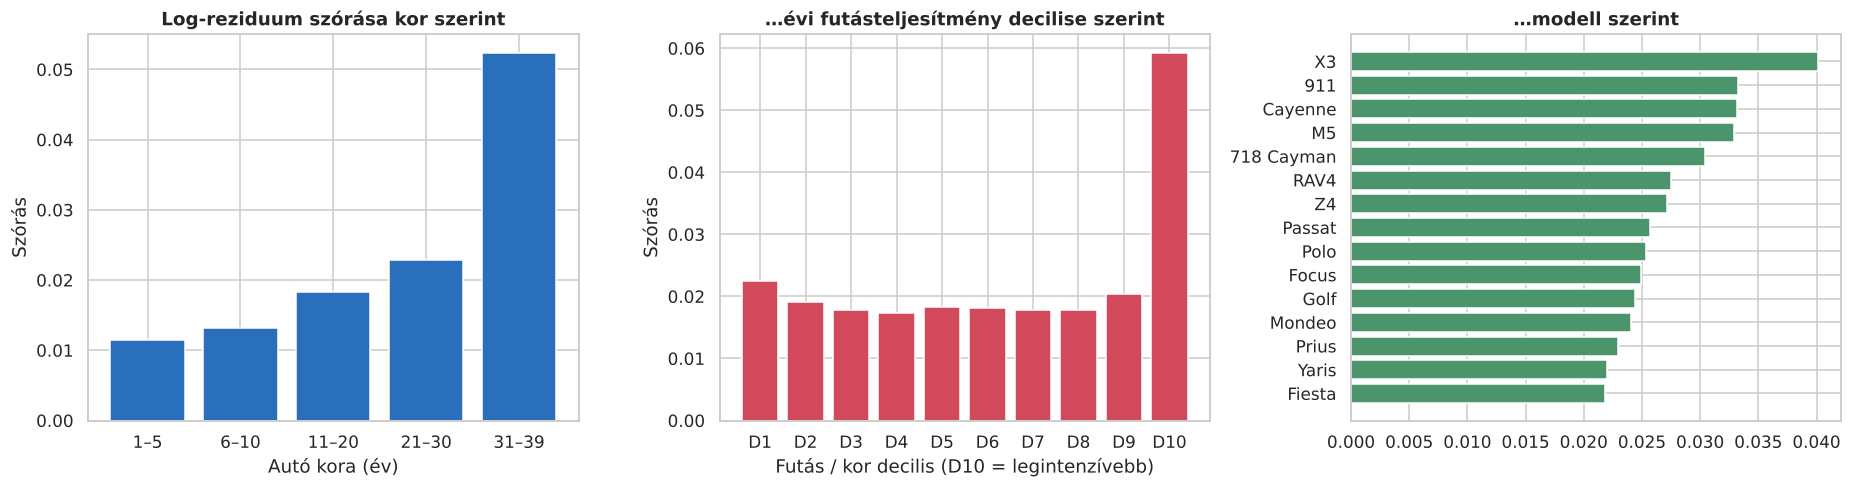

,n,átlag,szórás
kor_sáv,,,
1–5,3790,+0.0003,0.0114
6–10,6106,+0.0001,0.0131
11–20,12377,+0.0001,0.0183
21–30,12322,+0.0005,0.0228
31–39,5395,-0.0008,0.0524


,évi_futás_tól,évi_futás_ig,n,átlag,szórás
évi_futás_decilis,,,,,
D1,500,"3,427",4000,-0.0008,0.0225
D2,"3,427","4,326",3998,+0.0004,0.0191
D3,"4,326","4,949",3999,-0.0008,0.0178
D4,"4,949","5,482",3999,-0.0012,0.0174
D5,"5,482","6,005",3999,+0.0003,0.0182
D6,"6,005","6,515",3999,+0.0021,0.0181
D7,"6,515","7,038",3999,-0.0012,0.0177
D8,"7,039","7,670",3999,-0.0007,0.0177
D9,"7,670","8,525",3999,+0.0019,0.0205


,n,átlag,szórás
Model,,,
X3,1306,+0.0005,0.0401
911,698,+0.0035,0.0333
Cayenne,696,+0.0009,0.0332
M5,1316,+0.0025,0.0329
718 Cayman,694,+0.0005,0.0304
RAV4,3433,-0.0002,0.0275
Z4,1350,-0.0000,0.0272
Passat,3895,+0.0005,0.0257
Polo,3990,-0.0008,0.0253


In [22]:
diag["Mileage per year"] = diag["Mileage"] / diag["Car age"]
diag["kor_sáv"] = pd.cut(diag["Car age"], [0, 5, 10, 20, 30, 40], labels=["1–5", "6–10", "11–20", "21–30", "31–39"])
diag["évi_futás_decilis"] = pd.qcut(diag["Mileage per year"], 10, labels=[f"D{i}" for i in range(1, 11)])

seg_age = diag.groupby("kor_sáv", observed=True)["log_resid"].agg(n="size", átlag="mean", szórás="std")
seg_mpy = diag.groupby("évi_futás_decilis", observed=True).agg(
    évi_futás_tól=("Mileage per year", "min"), évi_futás_ig=("Mileage per year", "max"),
    n=("log_resid", "size"), átlag=("log_resid", "mean"), szórás=("log_resid", "std"))
seg_model = diag.groupby("Model")["log_resid"].agg(n="size", átlag="mean", szórás="std").sort_values("szórás", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].bar(seg_age.index.astype(str), seg_age["szórás"], color="#2a6fbb"); axes[0].set_title("Log-reziduum szórása kor szerint"); axes[0].set_xlabel("Autó kora (év)")
axes[1].bar(seg_mpy.index.astype(str), seg_mpy["szórás"], color="#d1495b"); axes[1].set_title("…évi futásteljesítmény decilise szerint"); axes[1].set_xlabel("Futás / kor decilis (D10 = legintenzívebb)")
axes[2].barh(seg_model.index[::-1], seg_model["szórás"][::-1], color="#4c956c"); axes[2].set_title("…modell szerint")
for ax in axes[:2]:
    ax.set_ylabel("Szórás")
plt.tight_layout(); plt.show()
display(seg_age.style.format({"átlag": "{:+.4f}", "szórás": "{:.4f}"}))
display(seg_mpy.style.format({"évi_futás_tól": "{:,.0f}", "évi_futás_ig": "{:,.0f}", "átlag": "{:+.4f}", "szórás": "{:.4f}"}))
display(seg_model.style.format({"átlag": "{:+.4f}", "szórás": "{:.4f}"}))

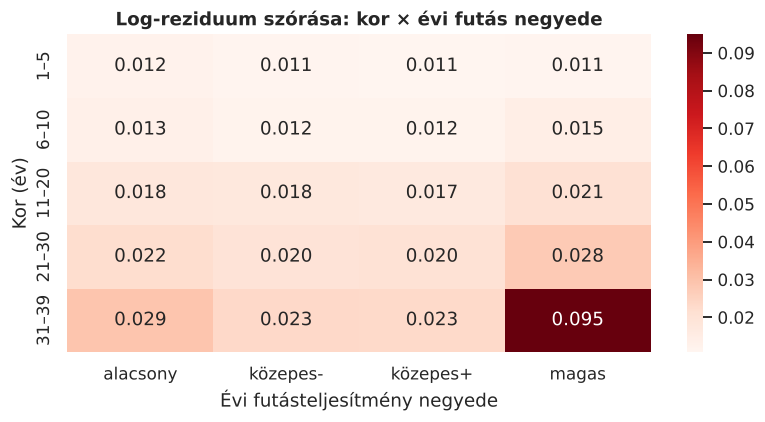

Mileage per year,alacsony,közepes-,közepes+,magas
kor_sáv,,,,
1–5,0.0121,0.0112,0.0108,0.0114
6–10,0.0133,0.0120,0.0120,0.0147
11–20,0.0177,0.0175,0.0169,0.0208
21–30,0.0221,0.0197,0.0204,0.0277
31–39,0.0291,0.0233,0.0231,0.0949


In [23]:
# Kereszt-szegmens: a régi autók közül melyiknél nagy a hiba? (kor × évi futás)
cross = diag.pivot_table(index="kor_sáv", columns=pd.qcut(diag["Mileage per year"], 4, labels=["alacsony", "közepes-", "közepes+", "magas"]),
                         values="log_resid", aggfunc="std", observed=True)
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(cross, annot=cross.map(lambda v: f"{v:.3f}"), fmt="", cmap="Reds", ax=ax)
ax.set_title("Log-reziduum szórása: kor × évi futás negyede"); ax.set_xlabel("Évi futásteljesítmény negyede"); ax.set_ylabel("Kor (év)")
plt.tight_layout(); plt.show()
display(cross.style.format("{:.4f}"))

**Mit látunk?**
- **Kor szerint:** a log-reziduum átlaga minden korsávban 0 közeli (nincs torzítás). A szórás viszont a korral folyamatosan nő: 1–5 éves autóknál 0,011, **31–39 éveseknél 0,052**, közel ötszörös.
- **Évi futás szerint:** a D1–D9 decilisekben a szórás 0,017–0,023, a **legintenzívebben használt 10%-ban (évi ~8 500–13 900 egység) 0,059**.
- **Modell szerint:** a modellek közti különbség jóval kisebb (a szórás kb. 0,02 és 0,04 között mozog), tehát nem egy-egy típus a gond.
- **Kor × évi futás:** a hiba a **régi és intenzíven használt** autóknál a legnagyobb. A 31–39 éves autók legintenzívebben használt negyedében a szórás 0,095, minden más cellában legfeljebb 0,029.

**Mit tennék?** A modell nem az egyes változókkal, hanem a **kor és a futás viszonyával** küzd. Ugyanaz a 300 000-es futás egészen mást jelent egy 15 és egy 38 éves autónál. A fa ezt az arányt csak sok egymás utáni vágással tudja közelíteni. Ez lesz a visszacsatolási kör hipotézise (18. fejezet).

### 17.4 Lehetetlen és extrém jóslatok

In [24]:
train_min, train_max = dev[TARGET].min(), dev[TARGET].max()
impossible = pd.Series({
    "negatív jóslat": int((diag["pred"] < 0).sum()),
    "a tanító legkisebb áránál olcsóbb jóslat": int((diag["pred"] < train_min).sum()),
    "a tanító legnagyobb áránál drágább jóslat": int((diag["pred"] > train_max).sum()),
    "50%-nál nagyobb relatív hiba": int((np.abs(diag["resid"]) / diag[TARGET] > 0.5).sum()),
    "20%-nál nagyobb relatív hiba": int((np.abs(diag["resid"]) / diag[TARGET] > 0.2).sum()),
}).to_frame("darab")
display(impossible)
worst = diag.assign(rel_hiba_pct=lambda d: (d["pred"] / d[TARGET] - 1) * 100).reindex(
    diag["log_resid"].abs().sort_values(ascending=False).index)[["Model", "Fuel type", "Engine size (L)", "Car age", "Mileage", TARGET, "pred", "rel_hiba_pct"]].head(8)
display(worst.style.format({"pred": "{:,.0f}", "rel_hiba_pct": "{:+.1f}", "Mileage": "{:,.0f}"}))

,darab
negatív jóslat,0
a tanító legkisebb áránál olcsóbb jóslat,0
a tanító legnagyobb áránál drágább jóslat,0
50%-nál nagyobb relatív hiba,14
20%-nál nagyobb relatív hiba,69


,Model,Fuel type,Engine size (L),Car age,Mileage,Price,pred,rel_hiba_pct
39549,X3,Diesel,3.000000,37,"446,897",167,417,+149.9
16584,Polo,Petrol,1.000000,36,"422,895",76,166,+118.4
36942,Golf,Hybrid,2.000000,34,"417,162",185,392,+112.0
2965,M5,Petrol,5.000000,35,"434,923",454,912,+100.8
26267,RAV4,Hybrid,2.200000,34,"416,143",285,546,+91.6
7570,Passat,Diesel,1.400000,38,"423,053",122,214,+75.1
21065,Mondeo,Diesel,2.000000,39,"423,108",129,214,+66.1
35574,Polo,Petrol,2.000000,35,"396,431",149,245,+64.3


**Mit látunk?** Negatív jóslat nincs (a log-cél ezt kizárja), és a tanító ártartományon kívüli jóslat sincs. A 39 990 autóból 69-nél nagyobb a relatív hiba 20%-nál, 14-nél 50%-nál. A legrosszabb esetek kivétel nélkül **34–39 éves, kb. 400 000-et futott autók** 76 és 454 közötti áron, amelyeket a modell 64–150%-kal **túlbecsül**.

**Mit tennék?** Ezek az autók az ártartomány alján, a „roncsérték” közelében vannak, ahol néhány tíz egységnyi abszolút eltérés is nagy relatív hiba. A modell itt túl optimista: nem tudja, hogy ennyi futás ilyen korban az átlagosnál is intenzívebb használatot jelent. Ez ugyanaz a jelenség, mint a 17.3 fejezetben, és ugyanazt a jellemzőt indokolja.

### 17.5 A lineáris alapmodell maradéka

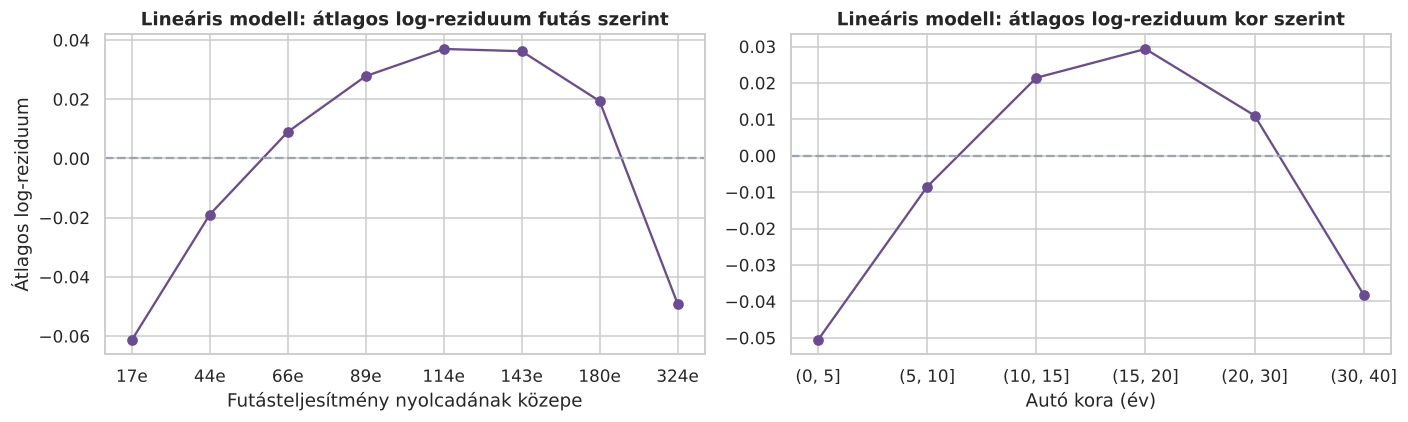

Átlagos log-reziduum futás-nyolcadonként: [-0.061 -0.019  0.009  0.028  0.037  0.036  0.019 -0.049]
Átlagos log-reziduum korsávonként:       [-0.051 -0.009  0.021  0.029  0.011 -0.038]


In [25]:
# A lineáris modell maradéka: van-e görbület, amit a lineáris forma nem fog meg?
lin_diag = dev.assign(log_resid=np.log1p(dev[TARGET]) - np.log1p(oof["Lineáris (Ridge, log-cél)"]))
lin_by_mileage = lin_diag.groupby(pd.qcut(lin_diag["Mileage"], 8), observed=True)["log_resid"].mean()
lin_by_age = lin_diag.groupby(pd.cut(lin_diag["Car age"], [0, 5, 10, 15, 20, 30, 40]), observed=True)["log_resid"].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot([f"{iv.mid/1000:.0f}e" for iv in lin_by_mileage.index], lin_by_mileage.values, marker="o", color="#6a4c93")
axes[0].axhline(0, color="#9aa5b1", linestyle="--"); axes[0].set_title("Lineáris modell: átlagos log-reziduum futás szerint")
axes[0].set_xlabel("Futásteljesítmény nyolcadának közepe"); axes[0].set_ylabel("Átlagos log-reziduum")
axes[1].plot([str(iv) for iv in lin_by_age.index], lin_by_age.values, marker="o", color="#6a4c93")
axes[1].axhline(0, color="#9aa5b1", linestyle="--"); axes[1].set_title("Lineáris modell: átlagos log-reziduum kor szerint")
axes[1].set_xlabel("Autó kora (év)")
plt.tight_layout(); plt.show()
print("Átlagos log-reziduum futás-nyolcadonként:", np.round(lin_by_mileage.values, 3))
print("Átlagos log-reziduum korsávonként:      ", np.round(lin_by_age.values, 3))

**Mit látunk?** A lineáris modell átlagos log-reziduuma futás szerint **fordított U** alakú. A nagyon kevés és a nagyon sok futású autókat túlbecsüli, a közepeseket alulbecsüli. Kor szerint hasonló a görbület. A futás hatása tehát nem lineáris a log-árban: az első kilométerek jobban csökkentik az árat, mint a későbbiek.

**Mit tennék?** A lineáris modellnek egy **log(futás)** változót adok. Ez a fáknak nem segít, mert a fa monoton transzformációra érzéketlen, a lineárisnak viszont kiegyenesítheti a görbét. Ez a második, kisebb hipotézis a visszacsatolási körben.

## 18. Visszacsatolási kör: a diagnosztikából következő új jellemző

**Hipotézis (H4):** a legjobb modell hibája a régi, intenzíven használt autóknál koncentrálódik (17.3–17.4). Ha a modell közvetlenül megkapja az **évi futásteljesítményt** (`Mileage / Car age`), ezt a viszonyt nem kell sok vágásból összeraknia, és a hiba csökken. Ez két oszlopból számolt hányados, amit egy fa nehezen tanul meg magától.

**Mellékhipotézis a lineárisra:** a **log(futás)** kiegyenesíti a 17.5 fejezetben talált görbületet.

**Szivárgás-ellenőrzés:** mindkét új jellemző soronként, csak bemeneti oszlopokból (futás, kor) számolódik, a célváltozót nem használja, és más sorokra sem támaszkodik. Ezért nem kell foldon belül illeszteni, és nem szivárogtat.

**Kísérleti elrendezés:** ugyanaz az 5 fold, ugyanazok a hiperparaméterek, csak a jellemzőkészlet változik. Az eredményt **foldonként páros különbségként** (javulás ± szórás) adjuk meg. Csak akkor nevezünk valamit javulásnak, ha az átlagos javulás nagyobb a foldok közti szórásnál, és lehetőleg mind az 5 foldon fennáll.

In [26]:
# Az új jellemző: két oszlopból számolt arány. Nem a célváltozóból számolódik, ezért nincs szivárgás,
# és soronként, a többi sortól függetlenül képezzük (nem kell foldon belül illeszteni).
for frame in (dev, test):
    frame["Mileage per year"] = frame["Mileage"] / frame["Car age"]   # Car age >= 1, nincs 0-val osztás
    frame["Log mileage"] = np.log1p(frame["Mileage"])
print(dev[["Mileage", "Car age", "Mileage per year"]].describe().T[["min", "50%", "max"]])

                    min            50%          max
Mileage           630.0  101221.000000  446897.0000
Car age             1.0      19.000000      39.0000
Mileage per year  500.0    6005.026923   13865.5625


In [27]:
def paired_comparison(name_a, pred_a, name_b, pred_b):
    a, b = fold_scores(y_dev, pred_a), fold_scores(y_dev, pred_b)
    d = a - b                                                 # > 0: a "b" változat a jobb
    return {"alap": name_a, "új": name_b, "alap RMSLE (foldátlag)": a.mean(), "új RMSLE (foldátlag)": b.mean(),
            "javulás foldonként": np.round(d, 4).tolist(), "javulás átlag": d.mean(), "javulás szórás": d.std(),
            "minden foldon jobb": bool((d > 0).all())}

experiments = {
    "Gradient boosting + évi futás": (make_boosting, NUM_FE),
    "Lineáris + log(futás)": (make_linear, NUM_BASE + ["Log mileage"]),
    "Lineáris + log(futás) + évi futás": (make_linear, NUM_BASE + ["Log mileage", "Mileage per year"]),
    "Random Forest + évi futás": (make_forest, NUM_FE),
}
for name, (mk, cols) in experiments.items():
    oof[name] = oof_predict(mk, cols)

comparisons = pd.DataFrame([
    paired_comparison("Gradient boosting (log-cél)", oof["Gradient boosting (log-cél)"], "Gradient boosting + évi futás", oof["Gradient boosting + évi futás"]),
    paired_comparison("Random Forest (log-cél)", oof["Random Forest (log-cél)"], "Random Forest + évi futás", oof["Random Forest + évi futás"]),
    paired_comparison("Lineáris (Ridge, log-cél)", oof["Lineáris (Ridge, log-cél)"], "Lineáris + log(futás)", oof["Lineáris + log(futás)"]),
    paired_comparison("Lineáris + log(futás)", oof["Lineáris + log(futás)"], "Lineáris + log(futás) + évi futás", oof["Lineáris + log(futás) + évi futás"]),
])
display(comparisons.style.format({"alap RMSLE (foldátlag)": "{:.4f}", "új RMSLE (foldátlag)": "{:.4f}", "javulás átlag": "{:+.4f}", "javulás szórás": "{:.4f}"}))

,alap,új,alap RMSLE (foldátlag),új RMSLE (foldátlag),javulás foldonként,javulás átlag,javulás szórás,minden foldon jobb
0,Gradient boosting (log-cél),Gradient boosting + évi futás,0.0259,0.0204,"[0.0057, 0.0052, 0.0053, 0.008, 0.0031]",+0.0055,0.0016,True
1,Random Forest (log-cél),Random Forest + évi futás,0.0437,0.0502,"[-0.0065, -0.0064, -0.0057, -0.0063, -0.0074]",-0.0065,0.0006,False
2,"Lineáris (Ridge, log-cél)",Lineáris + log(futás),0.0527,0.0365,"[0.0163, 0.0158, 0.0159, 0.0167, 0.0162]",+0.0162,0.0003,True
3,Lineáris + log(futás),Lineáris + log(futás) + évi futás,0.0365,0.0364,"[0.0001, 0.0001, 0.0001, 0.0001, 0.0001]",+0.0001,0.0000,True


**Eredmények:**

- **Gradient boosting + évi futás: a H4 teljesül.** Az RMSLE 0,0259-ról 0,0204-re csökkent (−21%). A javulás **mind az 5 foldon** megvan, átlaga 0,0055 ± 0,0016, vagyis kb. 3,5-szöröse a szórásnak. Ez tehát valódi javulás, nem véletlen ingadozás.
- **Random Forest + évi futás: rontott, és ezt őszintén rögzítjük.** Az RMSLE mind az 5 foldon nőtt (−0,0065 ± 0,0006). Lehetséges magyarázat (ezt nem mértük külön): vágásonként a változóknak csak a fele közül választ, az új, a korral és a futással erősen korreláló jellemző pedig „elveszi” a helyet a többitől, és a fák kevésbé pontos vágásokat kapnak. A tanulság: ugyanaz a jellemző modellcsaládonként eltérően hathat, ezért minden modellen külön kell mérni.
- **Lineáris + log(futás): a mellékhipotézis teljesül.** Az RMSLE 0,0527-ről 0,0365-re javult (0,0162 ± 0,0003, mind az 5 foldon), vagyis a görbület kiegyenesítése a lineárisnak sokat ad. **Az évi futás ezen felül a lineárisnak gyakorlatilag nem segít** (+0,0001): a javulás következetes, de a hiba 0,3%-a, gyakorlati jelentősége nincs.
- **Érdemes megjegyezni:** a feature engineering után a legjobb lineáris modell (0,0364) is gyengébb marad, mint a boosting új jellemző nélkül (0,0259). A H2 tehát a bővített jellemzőkkel is áll.

,szórás előtte (kor),szórás utána (kor),változás_%
kor_sáv,,,
1–5,0.011408,0.012169,+6.7
6–10,0.013127,0.012879,-1.9
11–20,0.018318,0.017453,-4.7
21–30,0.022794,0.022123,-2.9
31–39,0.052376,0.031226,-40.4


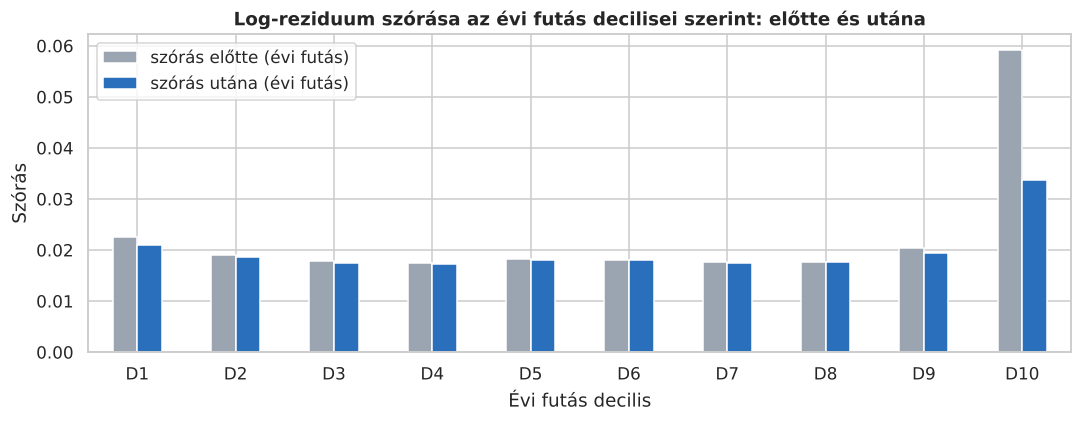

In [28]:
# Zárt-e a kör? Ugyanaz a szegmens-diagnosztika az új jellemzővel
after = dev.assign(log_resid=np.log1p(dev[TARGET]) - np.log1p(oof["Gradient boosting + évi futás"]))
after["kor_sáv"] = diag["kor_sáv"]; after["évi_futás_decilis"] = diag["évi_futás_decilis"]
before_after = pd.DataFrame({
    "szórás előtte (kor)": diag.groupby("kor_sáv", observed=True)["log_resid"].std(),
    "szórás utána (kor)": after.groupby("kor_sáv", observed=True)["log_resid"].std(),
})
before_after["változás_%"] = (before_after.iloc[:, 1] / before_after.iloc[:, 0] - 1) * 100
display(before_after.style.format("{:.4f}").format({"változás_%": "{:+.1f}"}))
mpy_ba = pd.DataFrame({
    "szórás előtte (évi futás)": diag.groupby("évi_futás_decilis", observed=True)["log_resid"].std(),
    "szórás utána (évi futás)": after.groupby("évi_futás_decilis", observed=True)["log_resid"].std(),
})
fig, ax = plt.subplots(figsize=(10, 4))
mpy_ba.plot(kind="bar", ax=ax, color=["#9aa5b1", "#2a6fbb"])
ax.set_title("Log-reziduum szórása az évi futás decilisei szerint: előtte és utána"); ax.set_xlabel("Évi futás decilis"); ax.set_ylabel("Szórás")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Zárult-e a kör?** Ugyanaz a szegmens-diagnosztika az új jellemzővel azt mutatja, hogy a javulás **pontosan ott** jelentkezik, ahol a hibát találtuk. A 31–39 éves autók log-reziduumának szórása **40%-kal** csökkent (0,052 → 0,031), a legintenzívebb évi futású decilisé is látványosan. A fiatalabb autóknál a változás kicsi, az 1–5 éveseknél enyhe romlás (+7%, 0,0114 → 0,0122). A diagnosztikából levezetett hipotézis tehát a hiba megtalált forrását célozta, és azt csökkentette.

**Ár:** a pénzegységben mért RMSE nem javult (342 → 349). Az új jellemző a relatív hibát, főleg az olcsó, régi autókét, csökkenti, a drága autók abszolút hibáját nem. Mivel a fő mutatót (RMSLE) előre rögzítettük, a döntés ennek alapján születik. Az RMSE-t a záró teszten is külön jelentjük.

## 19. Záró teszt: egyszer

**Előre rögzített szabály:** a záró tesztre a **legkisebb CV-RMSLE-jű** jelölt megy. A végleges modellt a **teljes fejlesztő halmazon** tanítjuk újra, ugyanazokkal a beállításokkal, majd **egyetlen egyszer** jóslunk a zárolt teszthalmazra. Összehasonlításként ugyanígy kiértékeljük a tisztességes lineáris alapmodellt, a naiv szabályt és az új jellemző nélküli boostingot is. Ezek nem jelöltek, csak viszonyítási pontok.

In [29]:
cv_table = pd.DataFrame({name: {"RMSLE": regression_metrics(y_dev, p)["RMSLE"], "RMSE": regression_metrics(y_dev, p)["RMSE"]}
                         for name, p in oof.items()}).T.sort_values("RMSLE")
display(cv_table.head(6).style.format({"RMSLE": "{:.4f}", "RMSE": "{:,.0f}"}))
FINAL_NAME = cv_table.index[0]
print("A záró tesztre előre rögzített modell (legkisebb CV-RMSLE):", FINAL_NAME)

,RMSLE,RMSE
Gradient boosting + évi futás,0.0204,349
Gradient boosting (log-cél),0.0259,342
Lineáris + log(futás) + évi futás,0.0364,"1,194"
Lineáris + log(futás),0.0365,"1,197"
Gradient boosting (nyers cél),0.0428,351
Random Forest (log-cél),0.0437,690


A záró tesztre előre rögzített modell (legkisebb CV-RMSLE): Gradient boosting + évi futás


In [30]:
def fit_predict(make_model, num_cols, train, target_rows):
    model = make_model(num_cols)
    model.fit(train[CAT + num_cols], np.log1p(train[TARGET]))
    return model, np.expm1(model.predict(target_rows[CAT + num_cols]))

final_model, test_pred = fit_predict(make_boosting, NUM_FE, dev, test)          # végleges: boosting + évi futás
_, test_pred_lin = fit_predict(make_linear, NUM_BASE, dev, test)                 # tisztességes lineáris alapmodell
_, test_pred_boost_base = fit_predict(make_boosting, NUM_BASE, dev, test)        # boosting új jellemző nélkül
test_pred_naive = naive_rule(dev, test)                                          # naiv szabály
y_test = test[TARGET].to_numpy()

test_results = pd.DataFrame({
    "Végleges: gradient boosting + évi futás": regression_metrics(y_test, test_pred),
    "Gradient boosting (alap jellemzők)": regression_metrics(y_test, test_pred_boost_base),
    "Lineáris (Ridge, log-cél)": regression_metrics(y_test, test_pred_lin),
    "Naiv szabály (modell × év medián)": regression_metrics(y_test, test_pred_naive),
}).T
display(test_results.style.format({"RMSLE": "{:.4f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "WAPE_%": "{:.2f}",
                                   "R2": "{:.4f}", "jósolt/tényleges összeg": "{:.4f}"}))

,RMSLE,RMSE,MAE,WAPE_%,R2,jósolt/tényleges összeg
Végleges: gradient boosting + évi futás,0.0194,310,161,1.17,0.9996,0.9996
Gradient boosting (alap jellemzők),0.0251,310,157,1.14,0.9996,0.9998
"Lineáris (Ridge, log-cél)",0.0532,"1,534",635,4.60,0.9912,1.0162
Naiv szabály (modell × év medián),0.3705,"3,068","2,062",14.94,0.9649,0.9784


**Értelmezés:** a végleges modell teszt-RMSLE-je 0,0194. Ez közel van a CV-becsléshez (0,0204), sőt kicsit jobb is, mert a végleges modell 25%-kal több adatból tanult. Túltanulásra vagy a teszten történt választásra utaló eltérés tehát nincs. A sorrend ugyanaz, mint a keresztvalidációban: végleges < boosting alap (0,0251) < lineáris (0,0532) < naiv szabály (0,3705). A teszten is látszik, hogy az évi futás a relatív hibát csökkenti, az RMSE-t gyakorlatilag nem (310 vs 310).

### 19.1 Bizonytalanság: bootstrap

In [31]:
B = 2000
n = len(y_test)
log_y = np.log1p(y_test)
sq_log = {name: (log_y - np.log1p(np.clip(p, 0, None))) ** 2 for name, p in
          [("final", test_pred), ("boost_base", test_pred_boost_base), ("lin", test_pred_lin), ("naive", test_pred_naive)]}
sq_abs_final = (y_test - test_pred) ** 2
boot = {k: [] for k in ["RMSLE", "RMSE", "Δ lineáris", "Δ naiv", "Δ boosting alap"]}
for _ in range(B):
    idx = rng.integers(0, n, n)                       # ugyanazok a sorok minden modellnél -> páros bootstrap
    r_final = np.sqrt(sq_log["final"][idx].mean())
    boot["RMSLE"].append(r_final)
    boot["RMSE"].append(np.sqrt(sq_abs_final[idx].mean()))
    boot["Δ lineáris"].append(np.sqrt(sq_log["lin"][idx].mean()) - r_final)
    boot["Δ naiv"].append(np.sqrt(sq_log["naive"][idx].mean()) - r_final)
    boot["Δ boosting alap"].append(np.sqrt(sq_log["boost_base"][idx].mean()) - r_final)

ci = pd.DataFrame({k: {"pontbecslés": (np.mean(v) if k.startswith("Δ") else None), "2,5%": np.percentile(v, 2.5), "97,5%": np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T
ci.loc["RMSLE", "pontbecslés"] = regression_metrics(y_test, test_pred)["RMSLE"]
ci.loc["RMSE", "pontbecslés"] = regression_metrics(y_test, test_pred)["RMSE"]
display(ci.style.format("{:.4f}").format({c: "{:,.1f}" for c in ci.columns}, subset=pd.IndexSlice["RMSE", :]))
print("Δ = az összehasonlított modell RMSLE-je mínusz a végleges modellé; ha az intervallum nem tartalmazza a 0-t, a végleges modell a teszten is biztosan jobb.")

,pontbecslés,"2,5%","97,5%"
RMSLE,0.0194,0.0189,0.0201
RMSE,309.7,291.0,330.8
Δ lineáris,0.0337,0.0327,0.0348
Δ naiv,0.3510,0.3441,0.3585
Δ boosting alap,0.0056,0.0028,0.0090


Δ = az összehasonlított modell RMSLE-je mínusz a végleges modellé; ha az intervallum nem tartalmazza a 0-t, a végleges modell a teszten is biztosan jobb.


Egy teszt-szám önmagában nem mutatja, mennyire bízhatunk benne. A teszthalmaz soraiból 2 000-szer húzunk visszatevéssel, és minden mintán újraszámoljuk a mutatókat. **Páros bootstrapot** használunk: minden mintavételnél ugyanazokat az autókat értékeljük minden modellnél, így a modellek közti különbség bizonytalansága is becsülhető. Időrend és ismétlődő autó nincs, ezért egyszerű, soronkénti bootstrap elegendő.

**Eredmény:**
- A végleges modell RMSLE-je 95%-os valószínűséggel **0,0189 és 0,0201** között van, az RMSE **291 és 331** között.
- **A lineáris alapmodellhez** képest a javulás 0,0337 (95%-os intervallum: 0,0327–0,0348), **a naiv szabályhoz** képest 0,351 (0,344–0,358).
- **Az új jellemző nélküli boostinghoz** képest 0,0056 (0,0028–0,0090).

Egyik intervallum sem tartalmazza a 0-t, tehát a végleges modell a teszten mindhárom viszonyítási pontnál bizonyíthatóan jobb. A visszacsatolási kör javulása is megmaradt a független teszten.

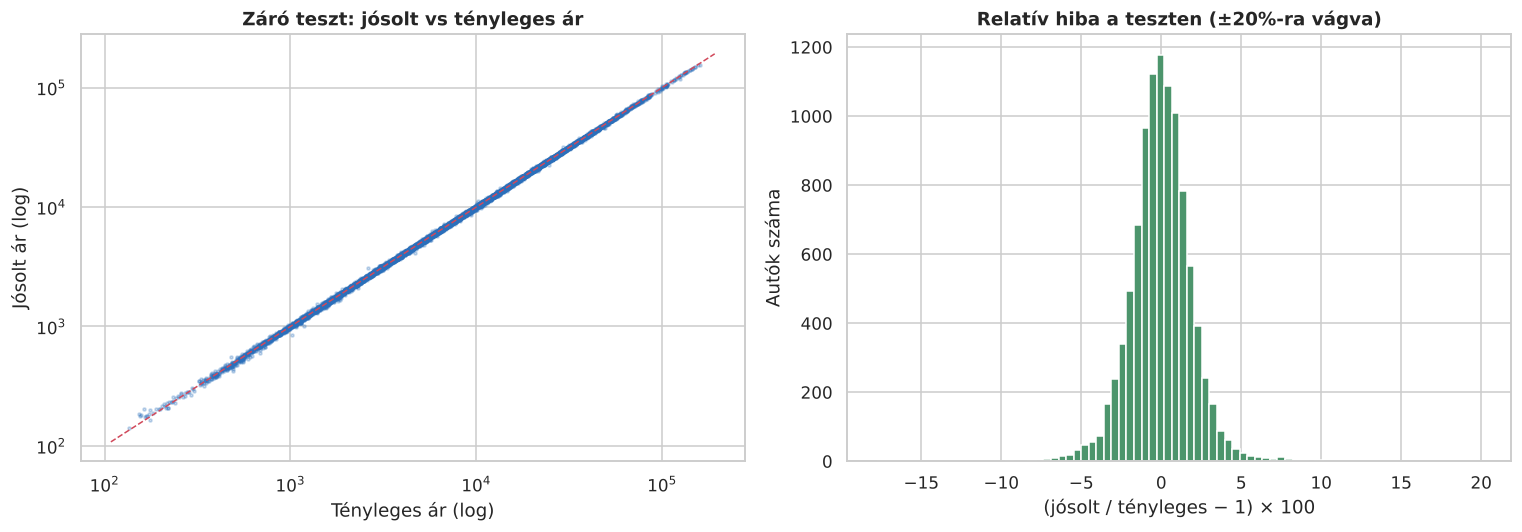

A teszt-autók 76.6%-ánál a jóslat ±2%-on belül van.
A teszt-autók 98.0%-ánál a jóslat ±5%-on belül van.
A teszt-autók 99.8%-ánál a jóslat ±10%-on belül van.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, test_pred, s=4, alpha=0.25, color="#2a6fbb")
lims = [y_test.min() * 0.8, y_test.max() * 1.2]
axes[0].plot(lims, lims, color="#d1495b", linestyle="--", linewidth=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Záró teszt: jósolt vs tényleges ár"); axes[0].set_xlabel("Tényleges ár (log)"); axes[0].set_ylabel("Jósolt ár (log)")
rel_err = (test_pred / y_test - 1) * 100
axes[1].hist(np.clip(rel_err, -20, 20), bins=80, color="#4c956c")
axes[1].set_title("Relatív hiba a teszten (±20%-ra vágva)"); axes[1].set_xlabel("(jósolt / tényleges − 1) × 100"); axes[1].set_ylabel("Autók száma")
plt.tight_layout(); plt.show()
for thr in (2, 5, 10):
    print(f"A teszt-autók {np.mean(np.abs(rel_err) <= thr) * 100:.1f}%-ánál a jóslat ±{thr}%-on belül van.")

**Gyakorlati olvasat:** a teszt-autók 76,6%-ánál a becslés ±2%-on, 98,0%-ánál ±5%-on, 99,8%-ánál ±10%-on belül van. A kereskedő szemszögéből ez azt jelenti, hogy a modell az autók túlnyomó részénél néhány százalékon belül eltalálja az árat. Ahol jelentősen téved, azok szinte kizárólag a nagyon régi, roncsérték közeli autók. Ezt a valóságban érdemes lenne a gépi becslésből kivenni és kézi értékelésre küldeni.

### 19.2 Példa: saját autó becslése

A végleges modellel bármely autó ára becsülhető, ha a bemenetei a tanító adatok tartományán belül esnek. A fa-alapú modell a tartományon kívül nem extrapolál, ezért a cella figyelmeztet, ha egy érték kilóg. A két Golf csak a futásban tér el: a modell szerint a +40 000 egységnyi futás kb. 5 400 egységgel (~25%-kal) csökkenti a becsült árat.

In [33]:
# Saját autó becslése a végleges modellel (az értékek átírhatók)
my_cars = pd.DataFrame([
    {"Model": "Golf", "Fuel type": "Diesel", "Engine size (L)": 2.0, "Car age": 8, "Mileage": 60000},
    {"Model": "Golf", "Fuel type": "Diesel", "Engine size (L)": 2.0, "Car age": 8, "Mileage": 100000},
    {"Model": "911", "Fuel type": "Petrol", "Engine size (L)": 3.0, "Car age": 5, "Mileage": 40000},
])
my_cars["Mileage per year"] = my_cars["Mileage"] / my_cars["Car age"]
my_cars["Becsült ár"] = np.expm1(final_model.predict(my_cars[CAT + NUM_FE])).round(0)
# Figyelmeztetés, ha egy bemenet kívül esik a tanító adatok tartományán (ott a fa nem extrapolál)
for col in NUM_FE:
    lo, hi = dev[col].min(), dev[col].max()
    outside = ~my_cars[col].between(lo, hi)
    if outside.any():
        print(f"FIGYELEM: {col} a tanító tartományán kívül ({lo:,.0f}–{hi:,.0f}) a(z) {list(my_cars.index[outside])}. sorban")
display(my_cars.style.format({"Mileage": "{:,.0f}", "Mileage per year": "{:,.0f}", "Becsült ár": "{:,.0f}"}))

,Model,Fuel type,Engine size (L),Car age,Mileage,Mileage per year,Becsült ár
0,Golf,Diesel,2.000000,8,"60,000","7,500","21,719"
1,Golf,Diesel,2.000000,8,"100,000","12,500","16,332"
2,911,Petrol,3.000000,5,"40,000","8,000","94,078"


## 20. A kutatás korlátai

1. **Az adat szimulált** (a forrás maga is *mock* adatként közli). A sorok 15,5%-ában a gyártási év megelőzi a modell piaci bevezetését, és az árak a valós piachoz képest irreálisan kevés zajt tartalmaznak (R² ≈ 0,9996). A modell tehát egy árképző szabályt tanult meg, nem a valódi használtautó-piacot. A 2%-os tipikus hiba valódi adaton nem várható, ott a sorrend (boosting > lineáris > naiv) a reálisabban átvihető tanulság, nem a pontos szám.
2. **Fontos ártényezők hiányoznak:** az eladás dátuma (így piaci ciklusok és infláció), az állapot, a felszereltség, a sebességváltó, az előző tulajdonosok száma és a földrajzi hely. Egy valós modellben ezek jelentős magyarázóerővel bírnának. Mivel nincs dátum, időrendi validáció sem volt lehetséges, pedig a valóságban mindig a múltból kell a jövőre jósolni.
3. **A modell nem extrapolál, és a ritka esetekben bizonytalan.** A tanító tartományon kívüli bemenetekre (például évi 20 000+ futás) a fák a tartomány széléhez tartozó értéket adják. A nagyon régi, roncsérték közeli autóknál a relatív hiba még a javítás után is többszöröse az átlagosnak.
4. **Módszertani egyszerűsítések:** a hiperparamétereket nem hangoltuk. Csak egy új jellemzőt próbáltunk ki a diagnosztikából (és egy mellékhipotézist a lineárisra), és a Random Forestnél tapasztalt romlás okát nem vizsgáltuk külön. A bootstrap-intervallum csak a teszthalmaz mintavételi bizonytalanságát méri, a modell tanítási ingadozását nem.

## 21. Összegzés

**A fő kérdésre adott válasz:** ezen az adaton egy használt autó ára öt alapadatból nagyon pontosan becsülhető. A végleges gradient boosting modell tipikus relatív hibája a független teszten **~1,9%** (RMSLE 0,0194; 95% CI 0,0189–0,0201). A legjobb modellcsalád a **gradient boosting**, a fő javulást a log-célváltozó és a diagnosztikából levezetett **évi futás** jellemző adta.

| Hipotézis | Eredmény | Bizonyíték |
|---|---|---|
| **H1** log-cél < nyers cél (RMSLE) | ✅ teljesül | boosting: 0,0259 vs 0,0428 (CV); a visszaalakítás torzítása elhanyagolható (0,9996) |
| **H2** fa-alapú ensemble > tisztességes lineáris | ✅ teljesül | 0,0259 vs 0,0527 (CV), mind az 5 foldon; a teszten is 0,0337-tel jobb (CI 0,0327–0,0348); log(futás)-sal bővített lineárissal szemben is |
| **H3** minden ML-modell > naiv szabály | ✅ teljesül | naiv: 0,364; a leggyengébb ML-modell (döntési fa) is 0,124 |
| **H4** évi futás a fa-alapú modellnek is segít | ⚠️ részben | boosting: −21% RMSLE, mind az 5 foldon (0,0055 ± 0,0016), a teszten is megmaradt (CI 0,0028–0,0090); **Random Forest: rontott** (−0,0065 ± 0,0006) |

**Mit tanultam a folyamatból?**

- A **baseline-ok** adják a számok értelmét: a 0,02-es RMSLE önmagában semmit sem mond, a naiv szabály 0,36-jához és a lineáris 0,05-jéhez képest viszont igen.
- A **diagnosztika** mutatta meg, hol érdemes javítani. Az új jellemző nem találgatásból jött, hanem abból, hogy a hiba a régi, sokat futott autóknál koncentrálódott. A javulás pontosan ott jelentkezett.
- Ugyanaz a jellemző **modellenként másképp hat**: a boostingnak segített, a Random Forestnek ártott, a lineárisnak közömbös volt.
- A „túl jó” eredmény **gyanút kell keltsen**. Itt nem szivárgás, hanem a szimulált adat magyarázza, és ezt a plauzibilitás-ellenőrzés tárta fel.

**Lehetséges következő lépések:** a módszer kipróbálása valódi hirdetési adaton (dátummal, időrendi validációval), hiperparaméter-hangolás keresztvalidációval, és kvantilis-modellek a becslés bizonytalanságának autónkénti megadására (például „90% eséllyel 9 500–10 200 között”).